**NAME-VAISHNAV BALPANDE\
SECTION-C2\
ROLL NO-B1-01\
SUBJECT-ML LAB\
PRACTICAL-CAPSTONE PROJECT**

**COLORVISION - MACHINE LEARNING BASED COLOUR SHADE CLASSIFICATION FROM SENSOR DATA**

**Objective:** build and compare machine learning models (classification and regression) that predict the colour shade of a surface from TCS34725 sensor readings (Red, Green, Blue, Clear).

In [344]:
import warnings
warnings.filterwarnings('ignore')

In [345]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [346]:
#Bigger fonts and lines so the plots are readable on a large screen
plt.rcParams.update({
    'figure.dpi':150,
    'font.size':19,
    'axes.titlesize':26,
    'axes.labelsize':23,
    'xtick.labelsize':19,
    'ytick.labelsize':19,
    'legend.fontsize':19,
    'lines.linewidth':4,
    'lines.markersize':12,
    'axes.titleweight':'bold'
})
sns.set_style("whitegrid")

**INPUT DATA**

In [347]:
df=pd.read_csv("Colour_DS.csv",encoding="utf-8-sig")

In [348]:
df.head()

,Date,Red,Green,Blue,Clear,Lux,R_Norm,G_Norm,B_Norm,R_Clear,G_Clear,B_Clear,HSV_V,HSV_S,HSV_H,LAB_L,LAB_A,LAB_B,Color,pH
0,10-04-2024 23:23,109,124,117,359,86.0,0.3114,0.3543,0.3343,0.3036,0.3454,0.3259,0.3543,0.1210,152.0000,65.2574,-4.0674,1.0483,Yellow,6.5
1,10-04-2024 23:24,147,51,49,243,49.0,0.5951,0.2065,0.1984,0.6049,0.2099,0.2016,0.5951,0.6667,1.2245,60.6536,29.7101,13.9829,Red,2.0
2,10-04-2024 23:25,2577,3238,1372,7330,2979.0,0.3586,0.4505,0.1909,0.3516,0.4417,0.1872,0.4505,0.5763,81.2540,70.3323,-15.9936,27.6935,Green,8.5
3,10-04-2024 23:25,3932,4395,3036,11656,3581.0,0.346,0.3868,0.2672,0.3373,0.3771,0.2605,0.3868,0.3092,80.4415,67.2383,-7.6348,12.4112,White,NaN
4,10-04-2024 23:26,278,293,228,807,229.0,0.3479,0.3667,0.2854,0.3445,0.3631,0.2825,0.3667,0.2218,73.8462,66.2781,-4.6069,8.664,Black,NaN


In [349]:
df.tail()

,Date,Red,Green,Blue,Clear,Lux,R_Norm,G_Norm,B_Norm,R_Clear,G_Clear,B_Clear,HSV_V,HSV_S,HSV_H,LAB_L,LAB_A,LAB_B,Color,pH
11087,28-05-2026,3870,3325,4500,11395,3140.0,0.3309,0.2843,0.3848,0.3396,0.2918,0.3949,0.3848,0.2611,267.8298,61.781,8.0118,-9.8404,Violet,14.0
11088,28-05-2026,4035,3495,4500,11865,3440.0,0.3354,0.2905,0.3741,0.3401,0.2946,0.3793,0.3741,0.2233,272.2388,62.177,7.1011,-8.0433,Violet,14.0
11089,28-05-2026,4200,3665,4500,12335,3765.0,0.3397,0.2964,0.3639,0.3405,0.2971,0.3648,0.3639,0.1856,278.4431,62.5479,6.2522,-6.3337,Violet,14.0
11090,28-05-2026,4365,3800,4500,12805,4115.0,0.3447,0.3,0.3553,0.3409,0.2968,0.3514,0.3553,0.1556,288.4286,62.8033,5.8135,-4.9532,Violet,14.0
11091,28-05-2026,4520,3800,4500,13275,4500.0,0.3526,0.2964,0.351,0.3405,0.2863,0.3390,0.3526,0.1593,301.6667,62.7011,6.6931,-4.5888,Violet,14.0


In [350]:
df.shape

(11092, 20)

In [351]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11092 entries, 0 to 11091
Data columns (total 20 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Date     11092 non-null  str    
 1   Red      11092 non-null  int64  
 2   Green    11092 non-null  int64  
 3   Blue     11092 non-null  int64  
 4   Clear    11092 non-null  int64  
 5   Lux      11091 non-null  float64
 6   R_Norm   11092 non-null  str    
 7   G_Norm   11092 non-null  str    
 8   B_Norm   11092 non-null  str    
 9   R_Clear  11092 non-null  float64
 10  G_Clear  11092 non-null  float64
 11  B_Clear  11092 non-null  float64
 12  HSV_V    11092 non-null  str    
 13  HSV_S    11092 non-null  float64
 14  HSV_H    11092 non-null  float64
 15  LAB_L    11092 non-null  str    
 16  LAB_A    11092 non-null  str    
 17  LAB_B    11092 non-null  str    
 18  Color    11092 non-null  str    
 19  pH       8779 non-null   float64
dtypes: float64(7), int64(4), str(9)
memory usage: 1.7 MB


In [352]:
df[["Red","Green","Blue","Clear","Lux"]].describe()

,Red,Green,Blue,Clear,Lux
count,11092.000000,11092.000000,11092.000000,11092.000000,11091.000000
mean,703.749279,834.016859,595.937342,2071.441039,563.373907
std,1097.675699,1389.291409,901.770990,3083.055190,933.122588
min,0.000000,0.000000,0.000000,10.000000,35.000000
25%,101.000000,135.000000,104.000000,458.000000,111.000000
50%,293.000000,349.000000,307.000000,963.000000,227.000000
75%,629.000000,659.000000,578.000000,1740.000000,438.000000
max,4978.000000,6442.000000,4543.000000,14654.000000,5226.000000


In [353]:
df.isnull().sum()

Date          0
Red           0
Green         0
Blue          0
Clear         0
Lux           1
R_Norm        0
G_Norm        0
B_Norm        0
R_Clear       0
G_Clear       0
B_Clear       0
HSV_V         0
HSV_S         0
HSV_H         0
LAB_L         0
LAB_A         0
LAB_B         0
Color         0
pH         2313
dtype: int64

In [354]:
df.duplicated().sum()

np.int64(94)

**DATA CLEANING**

In [355]:
#Colour names have mixed case/spaces e.g. 'lavender' and 'Lavender'
df["Color"]=df["Color"].astype(str).str.strip().str.title()
df["Color"].nunique()

32

In [356]:
df=df[df["Clear"]>0]
df=df[["Red","Green","Blue","Clear","Lux","Color"]].reset_index(drop=True)
df.shape

(11092, 6)

In [357]:
df["Color"].value_counts()

Color
Yellow          927
Brown           882
Sky Blue        840
Black           783
Purple          716
Golden          669
White           643
Lavender        640
Dark Blue       630
Green           584
Indigo          573
Rose            522
Tan             277
Lime            276
Gray            257
Pink            233
Olive           187
Red             172
Blue            136
Teal            101
Yellow-Green     96
Turquoise        96
Cyan             96
Royal Blue       96
Violet           96
Orange           91
Dark Green       86
Maroon           84
Brown-Orange     83
Amber            81
Mustard          79
Orange-Red       60
Name: count, dtype: int64

**UNIVARIATE ANALYSIS**

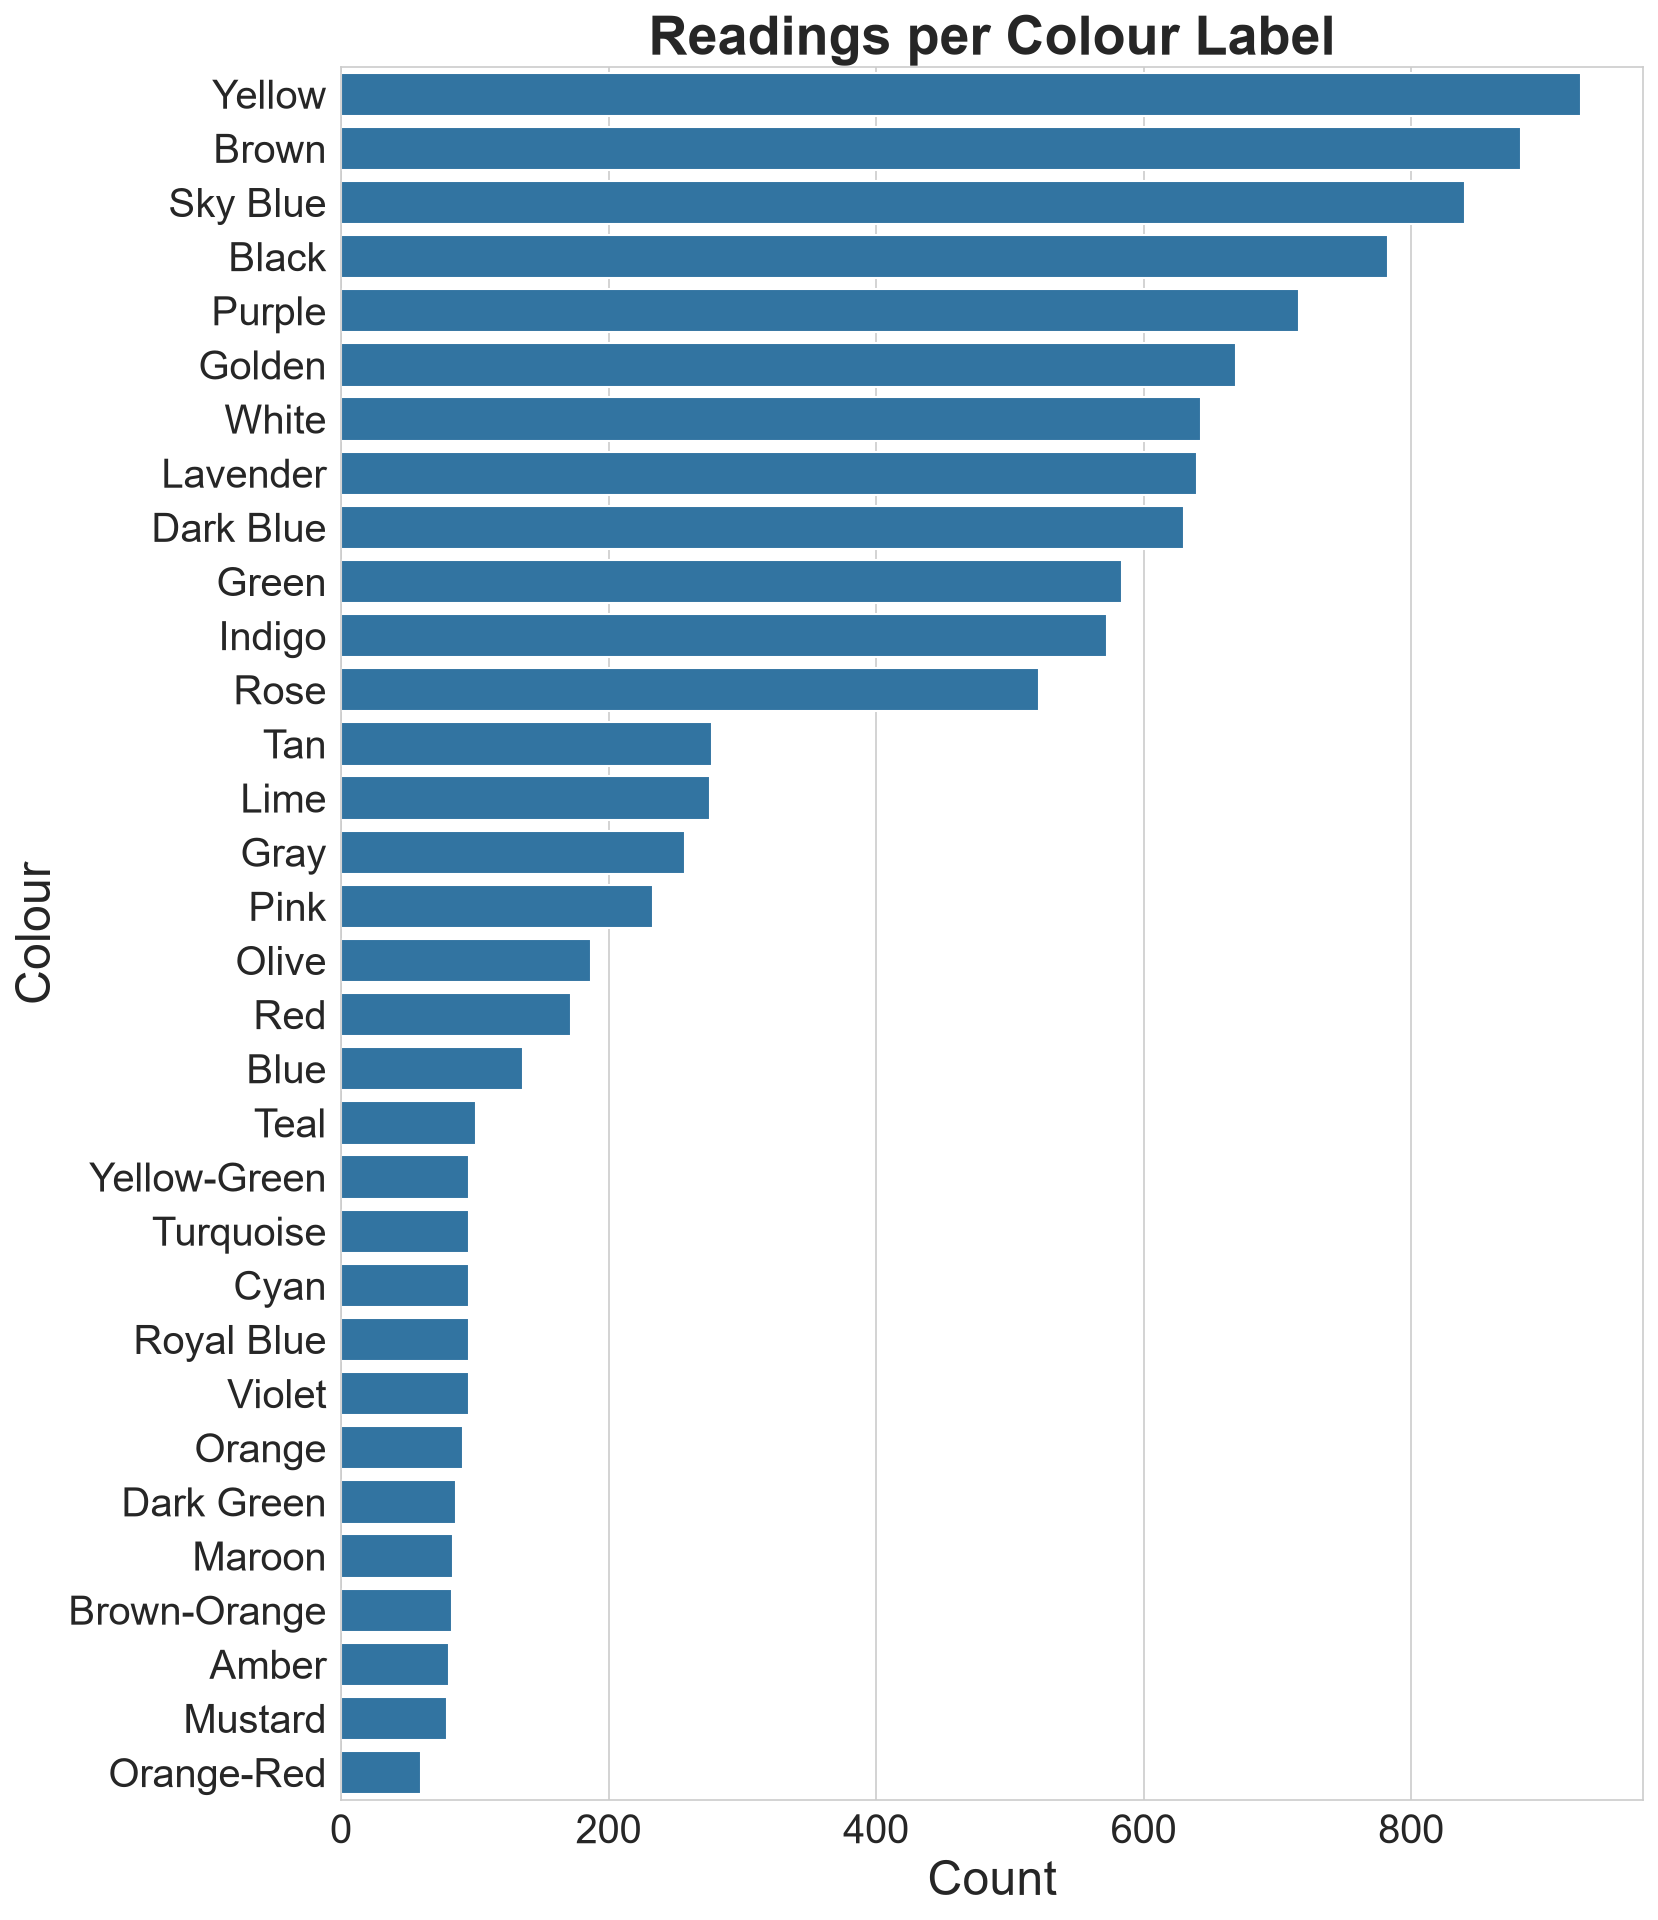

In [358]:
plt.figure(figsize=(11.2,15))
sns.countplot(y="Color",data=df,order=df["Color"].value_counts().index)
plt.title("Readings per Colour Label")
plt.xlabel("Count")
plt.ylabel("Colour")
plt.show()

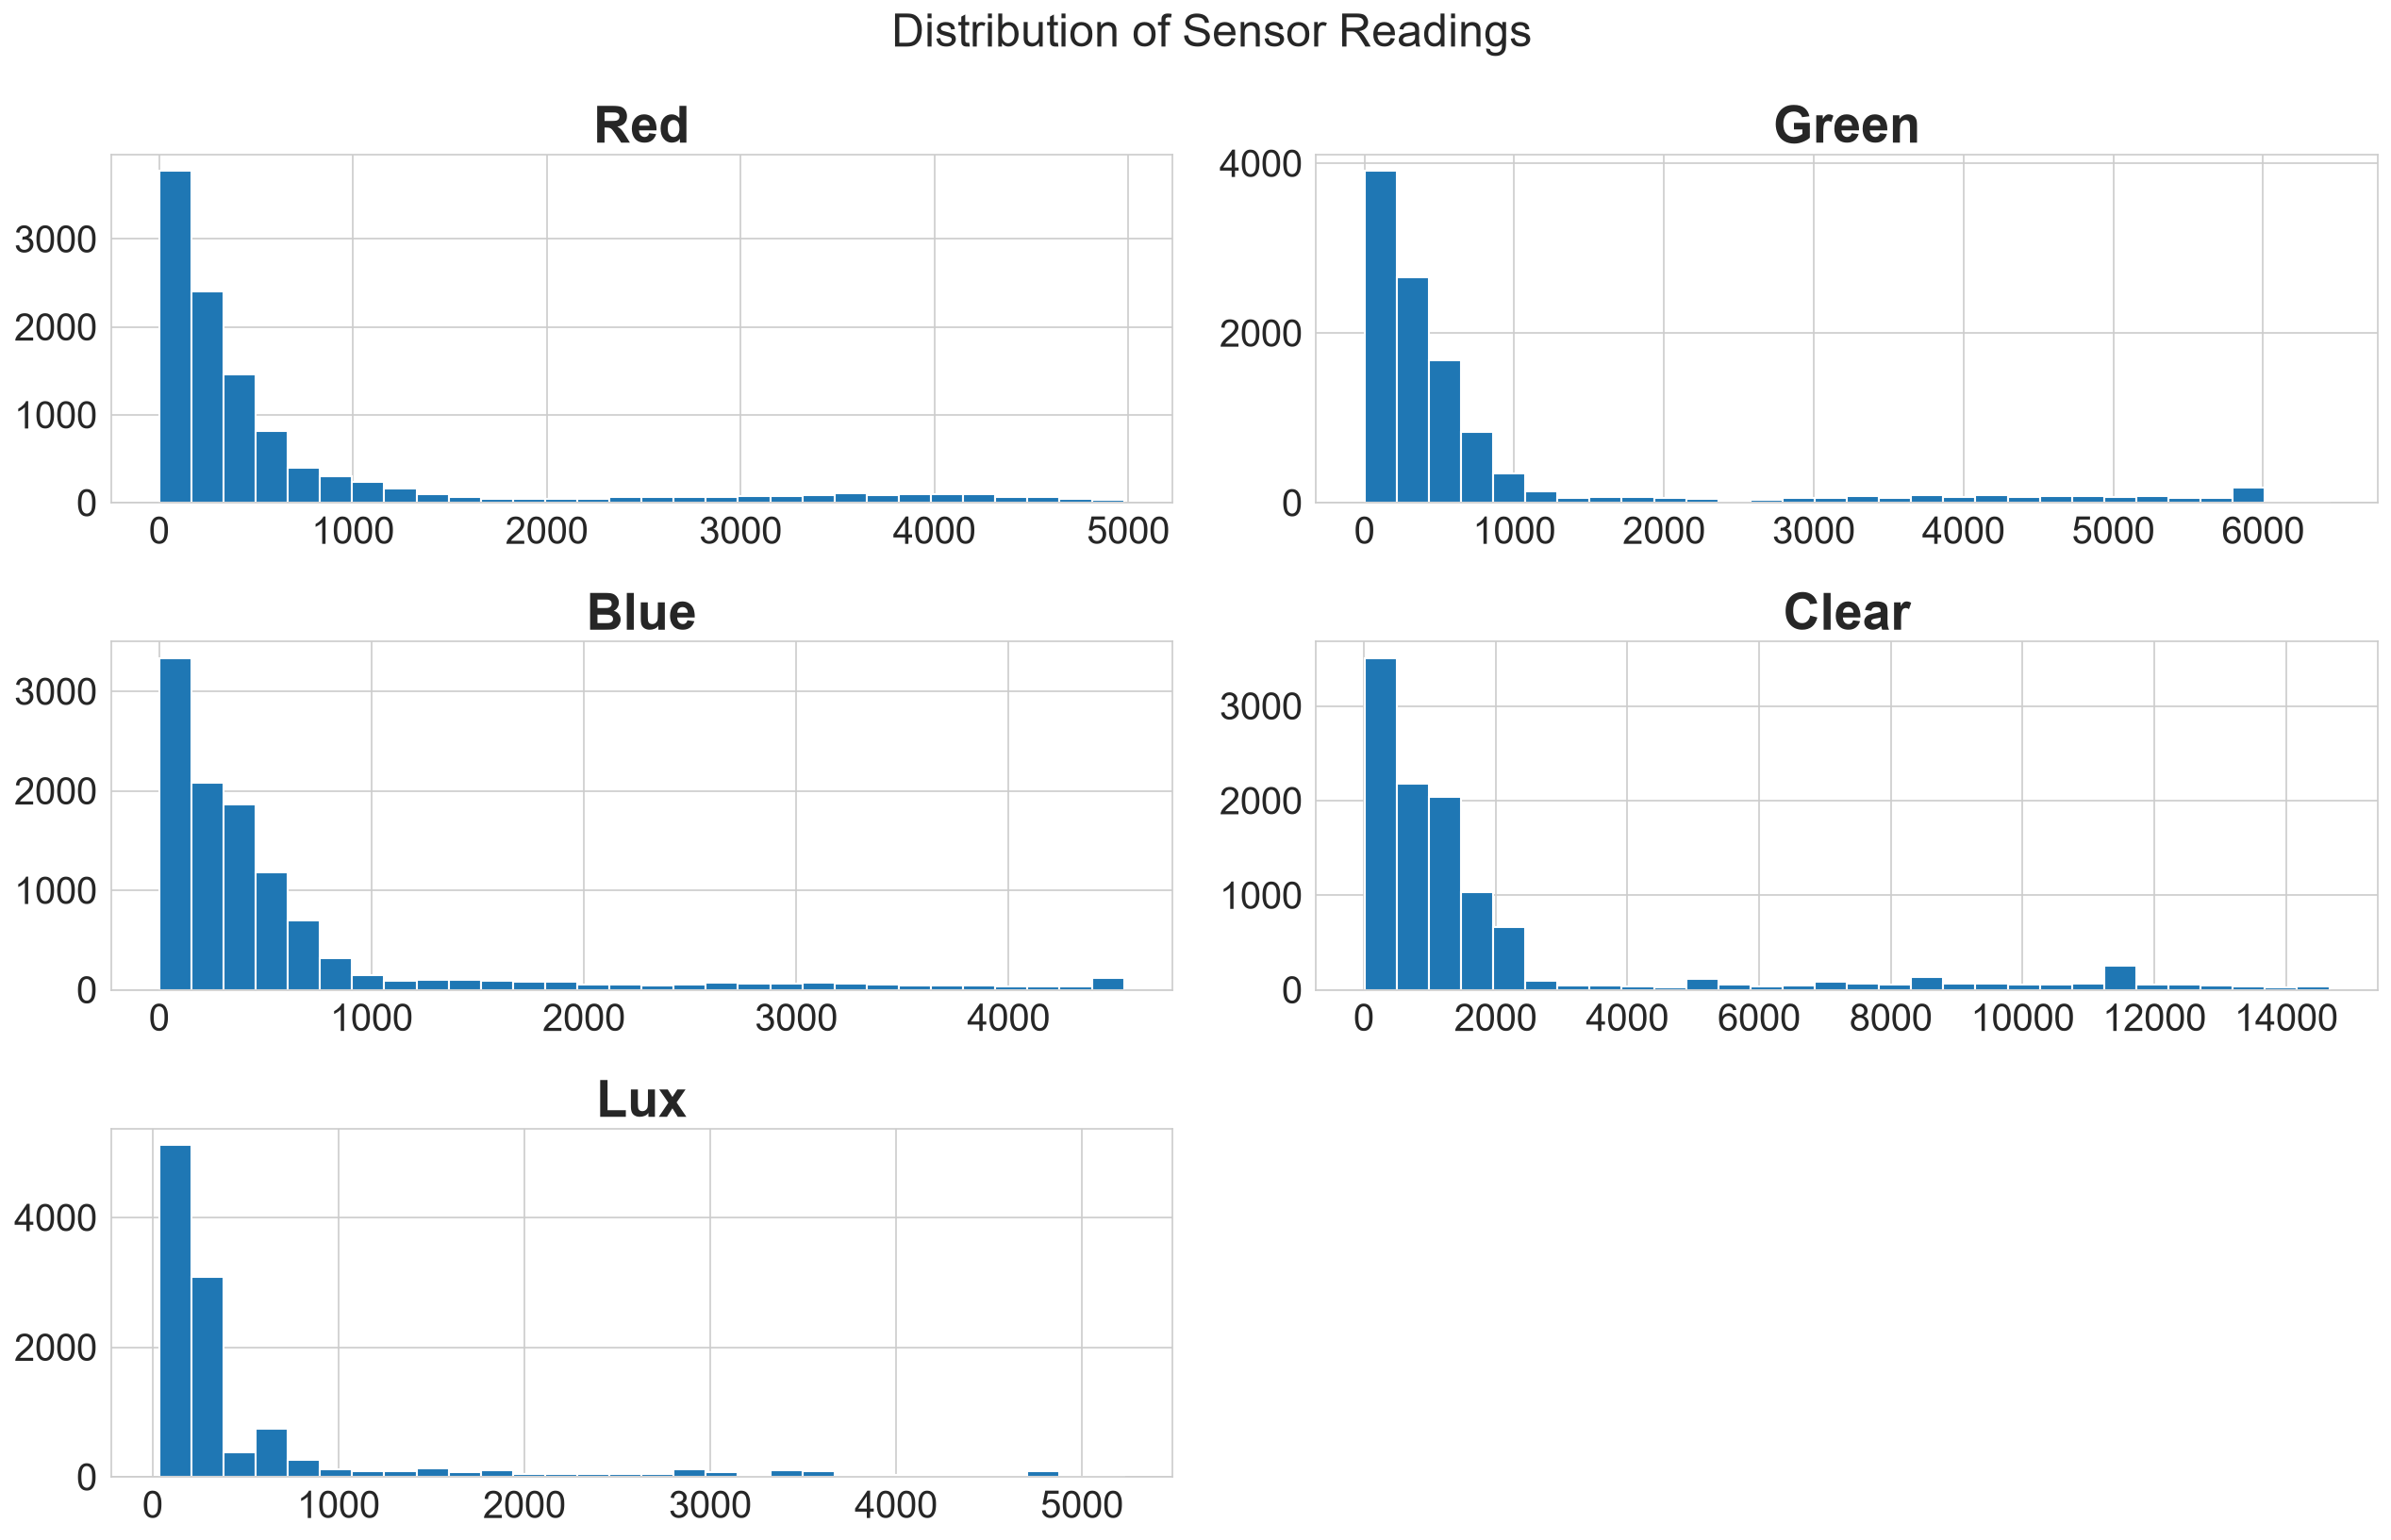

In [359]:
numerical_features=["Red","Green","Blue","Clear","Lux"]
df[numerical_features].hist(figsize=(17.5,11.2),bins=30)
plt.suptitle("Distribution of Sensor Readings")
plt.tight_layout()
plt.show()

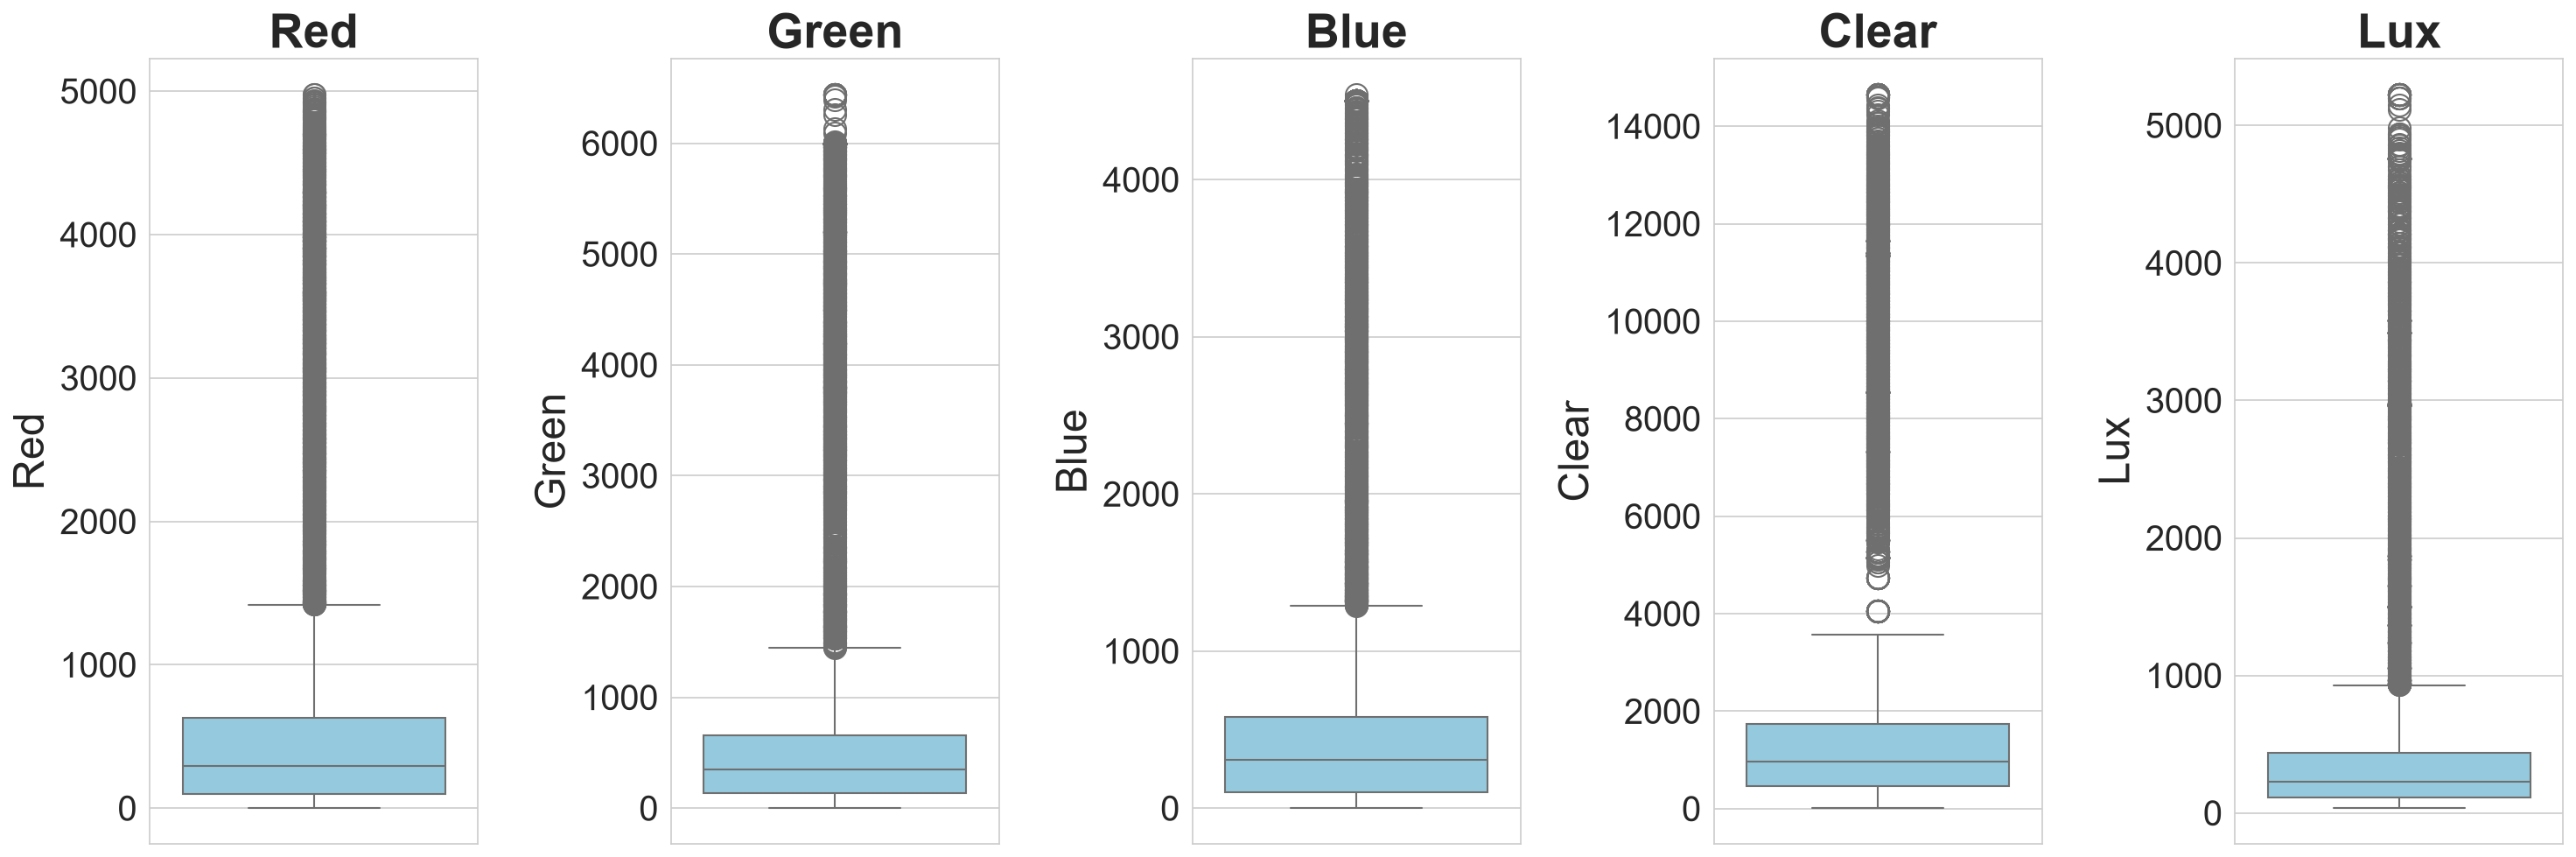

In [360]:
plt.figure(figsize=(20,6.9))
for i,column in enumerate(numerical_features,1):
    plt.subplot(1,5,i)
    sns.boxplot(y=df[column],color='skyblue')
    plt.title(column)
plt.tight_layout()
plt.show()

**MULTIVARIATE ANALYSIS**

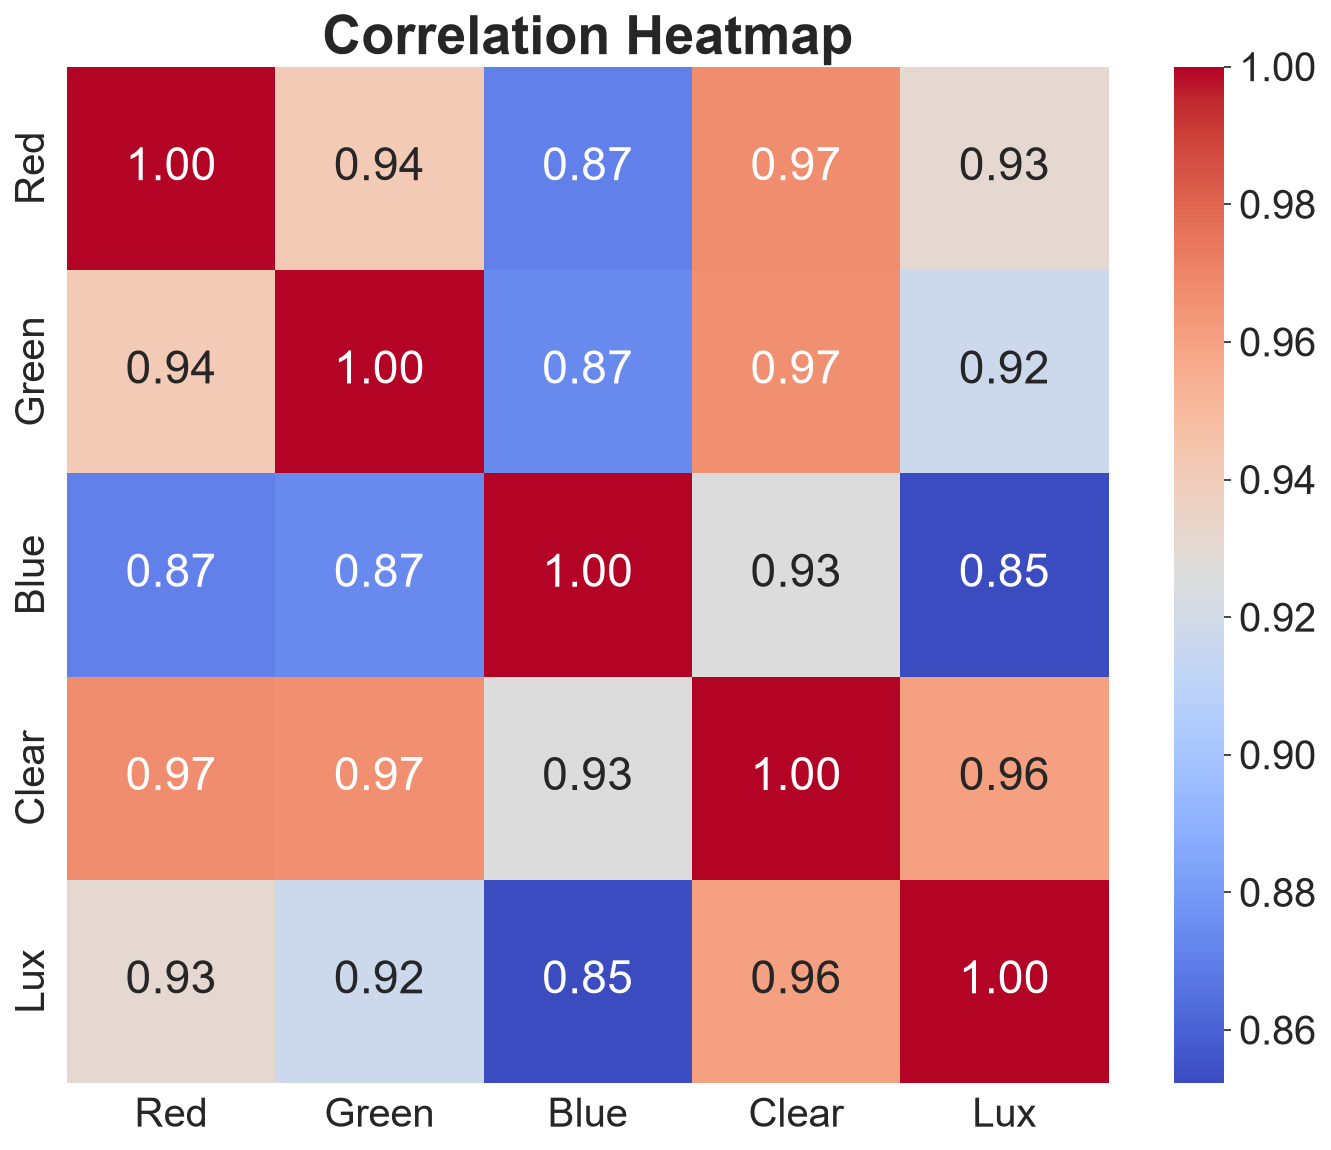

In [361]:
plt.figure(figsize=(11.2,8.8))
sns.heatmap(df[numerical_features].corr(),annot=True,cmap='coolwarm',fmt=".2f",annot_kws={"size":22})
plt.title("Correlation Heatmap")
plt.show()

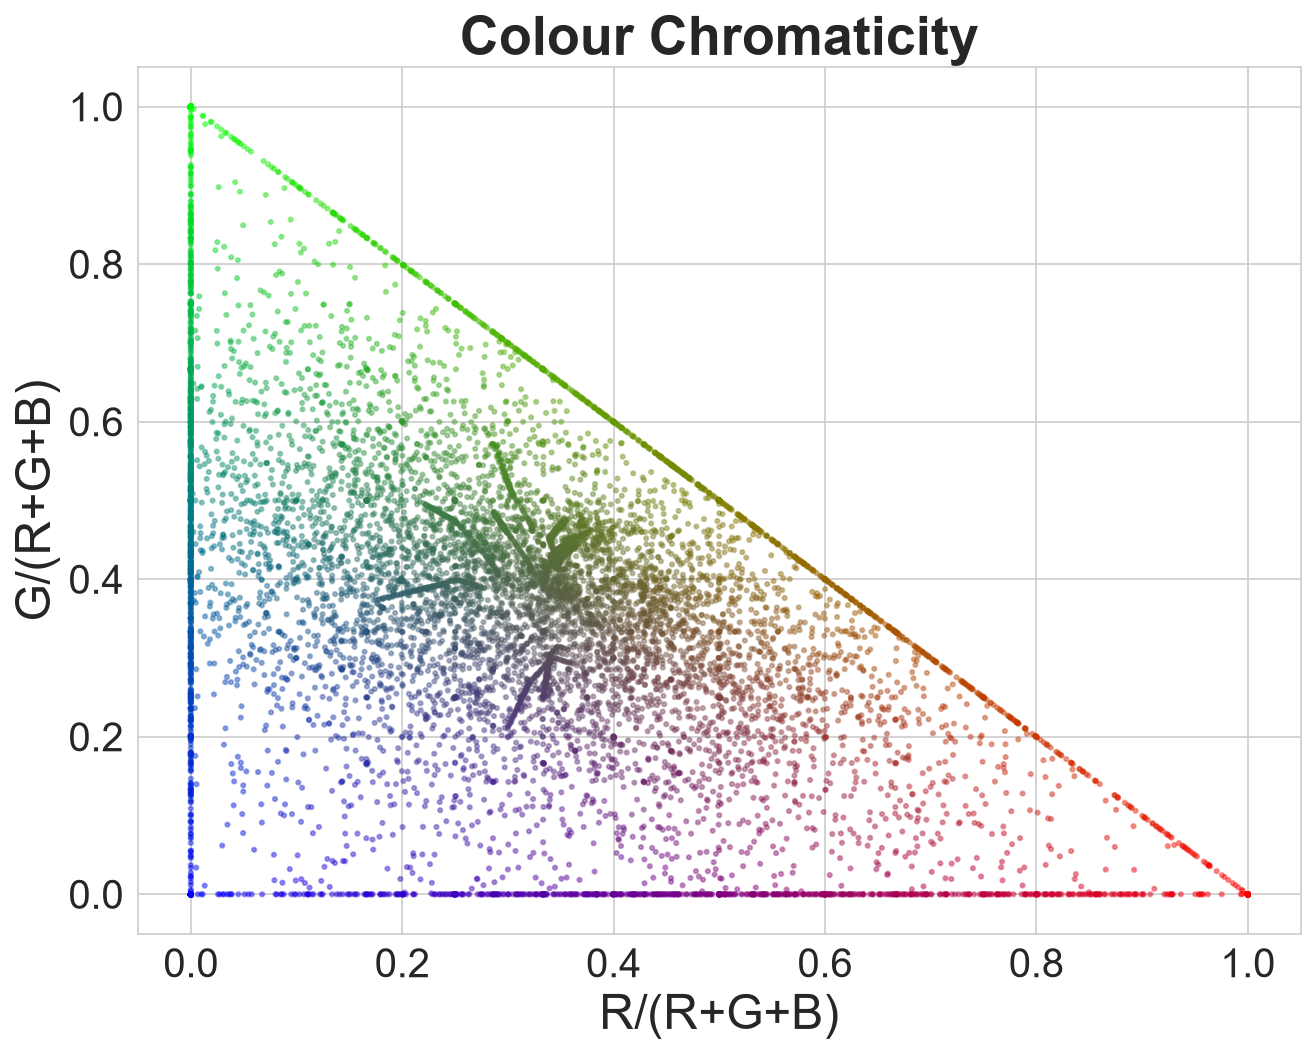

In [362]:
total=df["Red"]+df["Green"]+df["Blue"]
plt.figure(figsize=(10,7.5))
plt.scatter(df["Red"]/total,df["Green"]/total,s=4,alpha=0.4,c=np.column_stack([df["Red"]/total,df["Green"]/total,df["Blue"]/total]).clip(0,1))
plt.xlabel("R/(R+G+B)")
plt.ylabel("G/(R+G+B)")
plt.title("Colour Chromaticity")
plt.show()

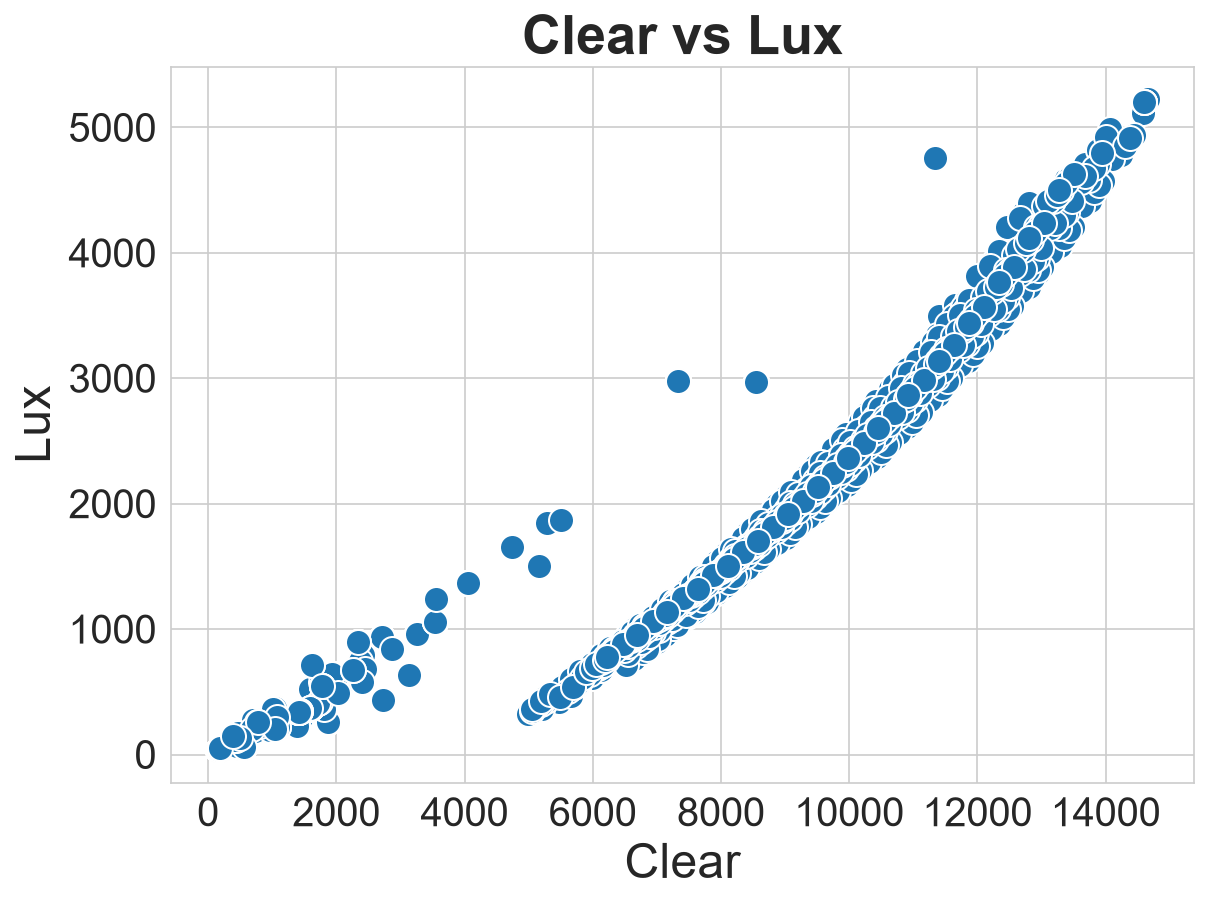

In [363]:
plt.figure(figsize=(8.8,6.2))
sns.scatterplot(x="Clear",y="Lux",data=df)
plt.title("Clear vs Lux")
plt.show()

**EDA OBSERVATIONS**
- No missing sensor values (only one missing Lux), 32 colour labels with imbalanced counts.
- Raw counts vary a lot with brightness (Clear 10 to 14654), so raw Red/Green/Blue are a poor input.
- Clear and Lux are strongly correlated (used for regression).
- Colour ratios form clusters, so ratio features are created next.

**FEATURE ENGINEERING**

In [364]:
def make_features(d):
    f=pd.DataFrame()
    total=(d["Red"]+d["Green"]+d["Blue"]).clip(lower=1)
    clear=d["Clear"].clip(lower=1)
    f["R_Norm"]=d["Red"]/total
    f["G_Norm"]=d["Green"]/total
    f["B_Norm"]=d["Blue"]/total
    f["R_Clear"]=(d["Red"]/clear).clip(upper=1)
    f["G_Clear"]=(d["Green"]/clear).clip(upper=1)
    f["B_Clear"]=(d["Blue"]/clear).clip(upper=1)
    mx=d[["Red","Green","Blue"]].max(axis=1)
    mn=d[["Red","Green","Blue"]].min(axis=1)
    f["Sat"]=(mx-mn)/mx.clip(lower=1)
    f["Val"]=mx/total
    f["Log_Clear"]=np.log1p(d["Clear"])
    return f

In [365]:
X=make_features(df)
y=df["Color"]
X.head()

,R_Norm,G_Norm,B_Norm,R_Clear,G_Clear,B_Clear,Sat,Val,Log_Clear
0,0.311429,0.354286,0.334286,0.303621,0.345404,0.325905,0.120968,0.354286,5.886104
1,0.595142,0.206478,0.198381,0.604938,0.209877,0.201646,0.666667,0.595142,5.497168
2,0.358564,0.450536,0.190900,0.351569,0.441746,0.187176,0.576282,0.450536,8.899867
3,0.346035,0.386782,0.267183,0.337337,0.377059,0.260467,0.309215,0.386782,9.363662
4,0.347935,0.366708,0.285357,0.344486,0.363073,0.282528,0.221843,0.366708,6.694562


In [366]:
print("X shape",X.shape)
print("y shape",y.shape)

X shape (11092, 9)
y shape (11092,)


In [367]:
FAMILY={"Red":"Red","Maroon":"Red","Orange-Red":"Red","Orange":"Orange","Brown-Orange":"Orange","Amber":"Orange",
        "Yellow":"Yellow","Golden":"Yellow","Mustard":"Yellow","Brown":"Brown","Tan":"Brown",
        "Green":"Green","Dark Green":"Green","Lime":"Green","Olive":"Green","Yellow-Green":"Green",
        "Blue":"Blue","Dark Blue":"Blue","Royal Blue":"Blue","Sky Blue":"Blue","Indigo":"Blue",
        "Cyan":"Cyan","Turquoise":"Cyan","Teal":"Cyan","Purple":"Purple","Violet":"Purple","Lavender":"Purple",
        "Pink":"Pink","Rose":"Pink","Black":"Black","White":"White","Gray":"Gray"}

**TRAIN TEST SPLIT**

In [368]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Training Samples:",X_train.shape[0])
print("Testing Samples:",X_test.shape[0])

Training Samples: 8873
Testing Samples: 2219


**LINEAR REGRESSION (Clear -> Lux)**

In [369]:
reg_df=df.dropna(subset=["Lux"])
X_reg=reg_df[["Clear"]]
y_reg=reg_df["Lux"]
X_train_r,X_test_r,y_train_r,y_test_r=train_test_split(X_reg,y_reg,test_size=0.2,random_state=42)

In [370]:
slr_model=LinearRegression()
slr_model.fit(X_train_r,y_train_r)
y_pred_slr=slr_model.predict(X_test_r)

In [371]:
print("Simple Linear Regression Results")
print("=================================")
print("MAE:",mean_absolute_error(y_test_r,y_pred_slr))
print("MSE:",mean_squared_error(y_test_r,y_pred_slr))
print("RMSE:",np.sqrt(mean_squared_error(y_test_r,y_pred_slr)))
print("R2:",r2_score(y_test_r,y_pred_slr))
print("Intercept:",slr_model.intercept_)
print("Slope:",slr_model.coef_[0])

Simple Linear Regression Results
MAE: 124.46619731200045
MSE: 63003.56253471209
RMSE: 251.00510459891467
R2: 0.929204115573617
Intercept: -39.33058221243209
Slope: 0.29076865978291094


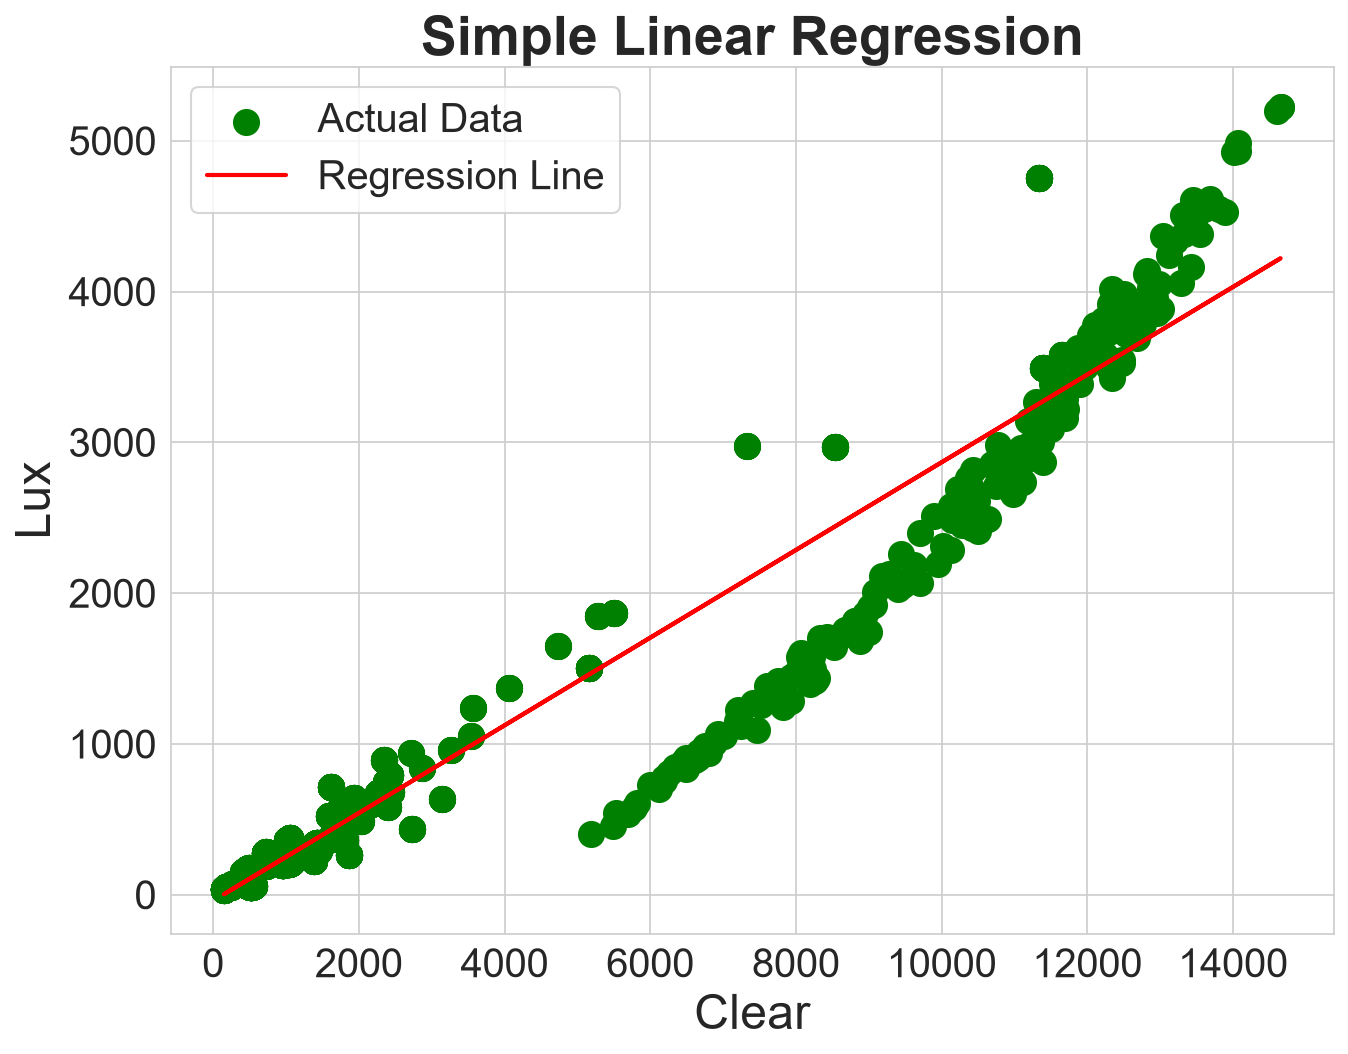

In [372]:
plt.figure(figsize=(10,7.5))
plt.scatter(X_test_r,y_test_r,color='green',label='Actual Data')
plt.plot(X_test_r,y_pred_slr,color='red',linewidth=2,label='Regression Line')
plt.xlabel("Clear")
plt.ylabel("Lux")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

In [373]:
X_mlr=reg_df[["Red","Green","Blue","Clear"]]
X_train_m,X_test_m,y_train_m,y_test_m=train_test_split(X_mlr,y_reg,test_size=0.2,random_state=42)
mlr=LinearRegression()
mlr.fit(X_train_m,y_train_m)
y_pred_mlr=mlr.predict(X_test_m)
print("Multiple Linear Regression Results")
print("=================================")
print("MAE:",mean_absolute_error(y_test_m,y_pred_mlr))
print("RMSE:",np.sqrt(mean_squared_error(y_test_m,y_pred_mlr)))
print("R2:",r2_score(y_test_m,y_pred_mlr))

Multiple Linear Regression Results
MAE: 131.24695511784486
RMSE: 223.9264581164789
R2: 0.9436552150105485


**KNN REGRESSION (Red, Green, Blue, Clear -> Lux)**

Best K for Regression: 2 with R2 Score: 0.9939


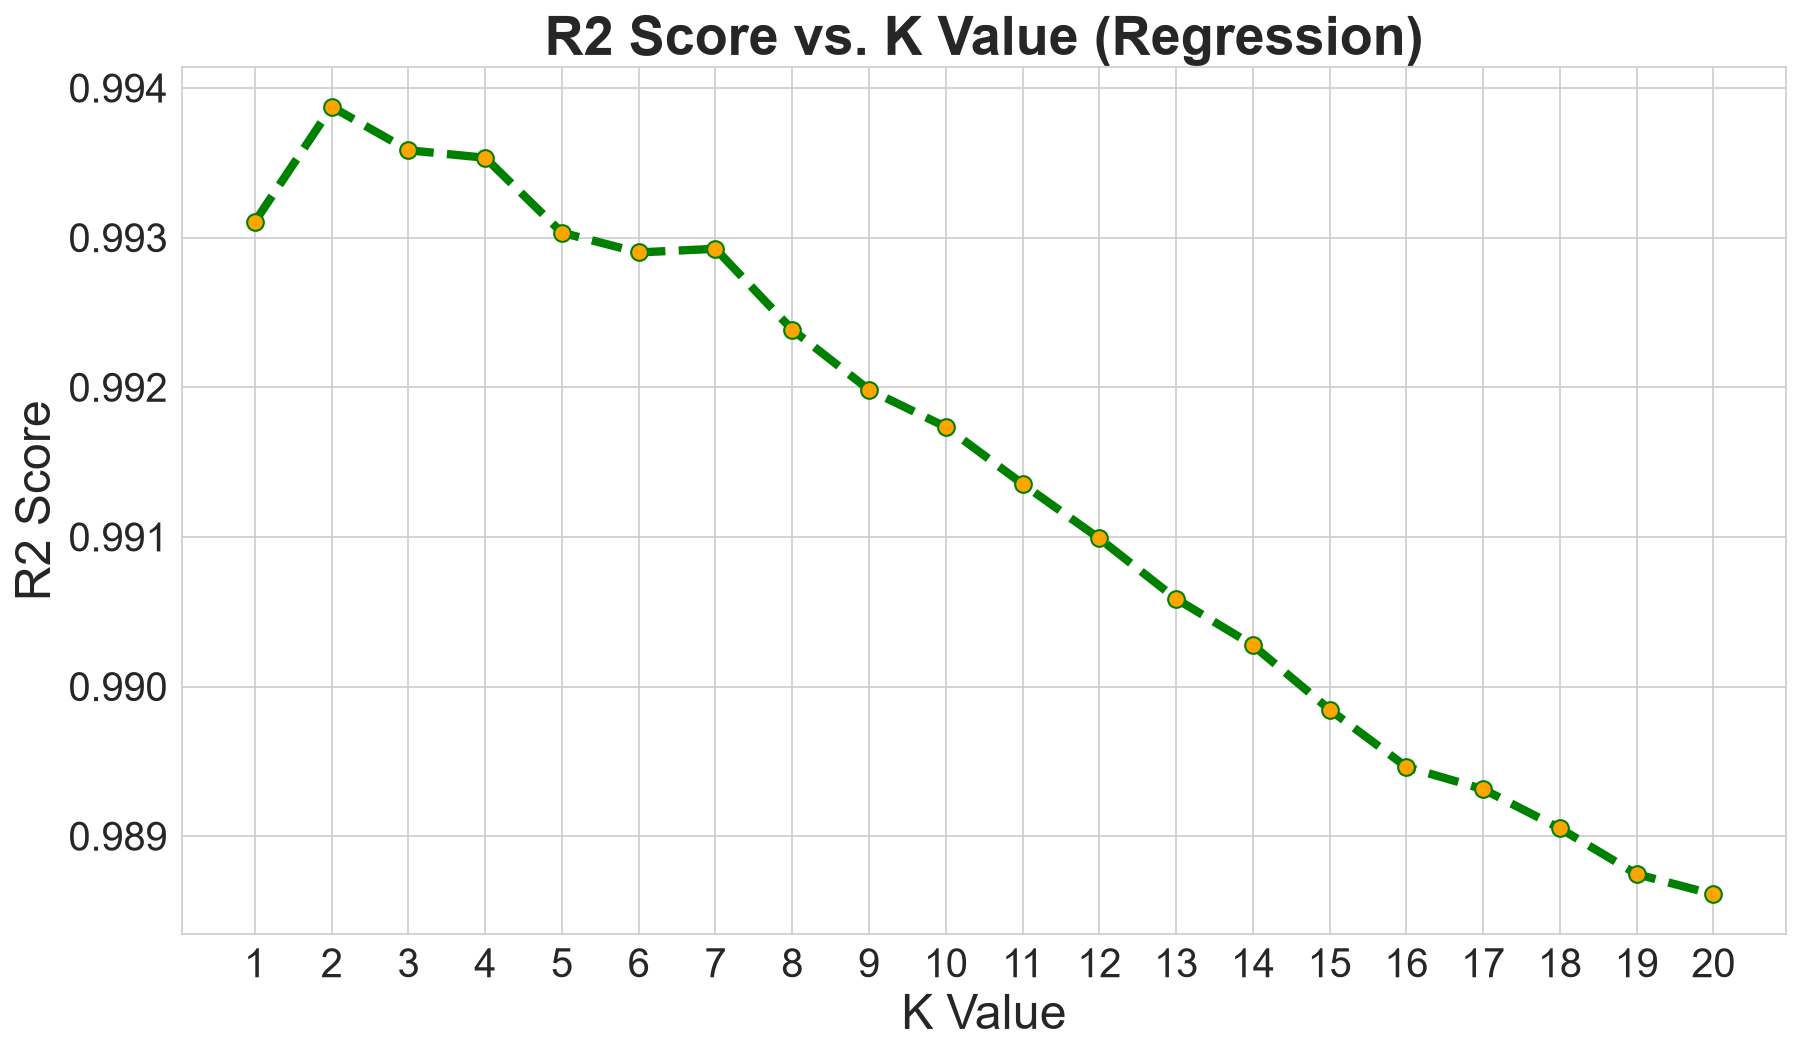

In [374]:
scaler_reg=StandardScaler()
X_train_m_scaled=scaler_reg.fit_transform(X_train_m)
X_test_m_scaled=scaler_reg.transform(X_test_m)

k_values=range(1,21)
r2_scores=[]
for k in k_values:
    reg=KNeighborsRegressor(n_neighbors=k)
    reg.fit(X_train_m_scaled,y_train_m)
    r2_scores.append(r2_score(y_test_m,reg.predict(X_test_m_scaled)))

best_k_r=k_values[np.argmax(r2_scores)]
print(f"Best K for Regression: {best_k_r} with R2 Score: {max(r2_scores):.4f}")

plt.figure(figsize=(13.8,7.5))
plt.plot(k_values,r2_scores,marker='o',linestyle='dashed',color='green',markerfacecolor='orange',markersize=8)
plt.title('R2 Score vs. K Value (Regression)')
plt.xlabel('K Value')
plt.ylabel('R2 Score')
plt.xticks(k_values)
plt.show()

In [375]:
best_reg=KNeighborsRegressor(n_neighbors=best_k_r)
best_reg.fit(X_train_m_scaled,y_train_m)
y_pred_knr=best_reg.predict(X_test_m_scaled)
print("Regression Metrics:")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test_m,y_pred_knr):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test_m,y_pred_knr)):.4f}")
print(f"R-squared (R2): {r2_score(y_test_m,y_pred_knr):.4f}")

Regression Metrics:
Mean Squared Error (MSE): 5451.1421
Root Mean Squared Error (RMSE): 73.8318
R-squared (R2): 0.9939


**KNN CLASSIFICATION (Predicting Colour)**

Best K for Classification: 6 with accuracy: 0.4281


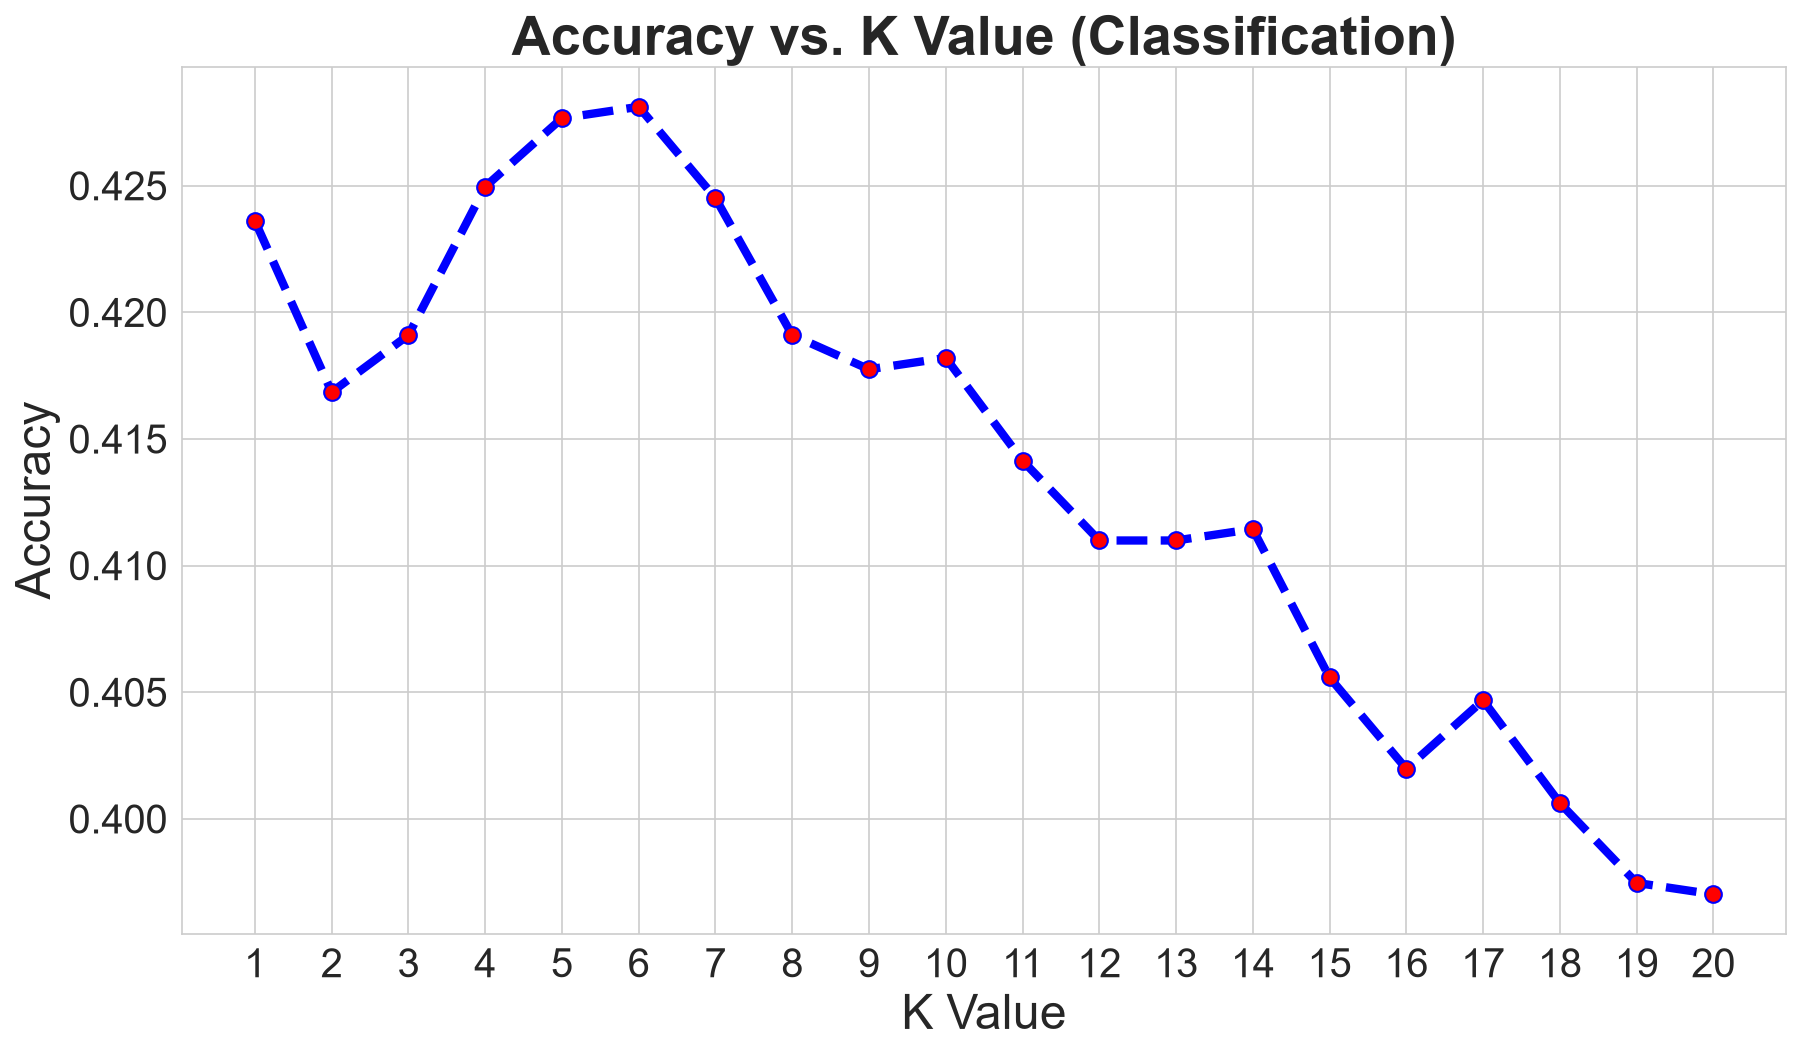

In [376]:
scaler_class=StandardScaler()
X_train_scaled=scaler_class.fit_transform(X_train)
X_test_scaled=scaler_class.transform(X_test)

accuracies=[]
for k in k_values:
    clf=KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_train_scaled,y_train)
    accuracies.append(accuracy_score(y_test,clf.predict(X_test_scaled)))

best_k_c=k_values[np.argmax(accuracies)]
print(f"Best K for Classification: {best_k_c} with accuracy: {max(accuracies):.4f}")

plt.figure(figsize=(13.8,7.5))
plt.plot(k_values,accuracies,marker='o',linestyle='dashed',color='blue',markerfacecolor='red',markersize=8)
plt.title('Accuracy vs. K Value (Classification)')
plt.xlabel('K Value')
plt.ylabel('Accuracy')
plt.xticks(k_values)
plt.show()

In [377]:
knn=KNeighborsClassifier(n_neighbors=best_k_c)
knn.fit(X_train_scaled,y_train)
y_pred_knn=knn.predict(X_test_scaled)

In [378]:
accuracy_knn=accuracy_score(y_test,y_pred_knn)
precision_knn=precision_score(y_test,y_pred_knn,average='weighted')
recall_knn=recall_score(y_test,y_pred_knn,average='weighted')
f1_knn=f1_score(y_test,y_pred_knn,average='weighted')
print("KNN Results")
print("Accuracy:",accuracy_knn)
print("Precision:",precision_knn)
print("Recall:",recall_knn)
print("F1 Score:",f1_knn)

KNN Results
Accuracy: 0.4281207751239297
Precision: 0.44033314955228164
Recall: 0.4281207751239297
F1 Score: 0.4227478346080662


**DECISION TREE**

In [379]:
dt_model=DecisionTreeClassifier(criterion='entropy',random_state=42)
dt_model.fit(X_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samp

In [380]:
y_train_pred_dt=dt_model.predict(X_train)
y_pred_dt=dt_model.predict(X_test)

In [381]:
print("Training Accuracy",accuracy_score(y_train,y_train_pred_dt))
print("Testing Accuracy",accuracy_score(y_test,y_pred_dt))

Training Accuracy 1.0
Testing Accuracy 0.975214060387562


In [382]:
accuracy_dt=accuracy_score(y_test,y_pred_dt)
precision_dt=precision_score(y_test,y_pred_dt,average='weighted')
recall_dt=recall_score(y_test,y_pred_dt,average='weighted')
f1_dt=f1_score(y_test,y_pred_dt,average='weighted')
print("Precision:",precision_dt)
print("Recall:",recall_dt)
print("F1 Score:",f1_dt)

Precision: 0.9758003560994979
Recall: 0.975214060387562
F1 Score: 0.9752303858275686


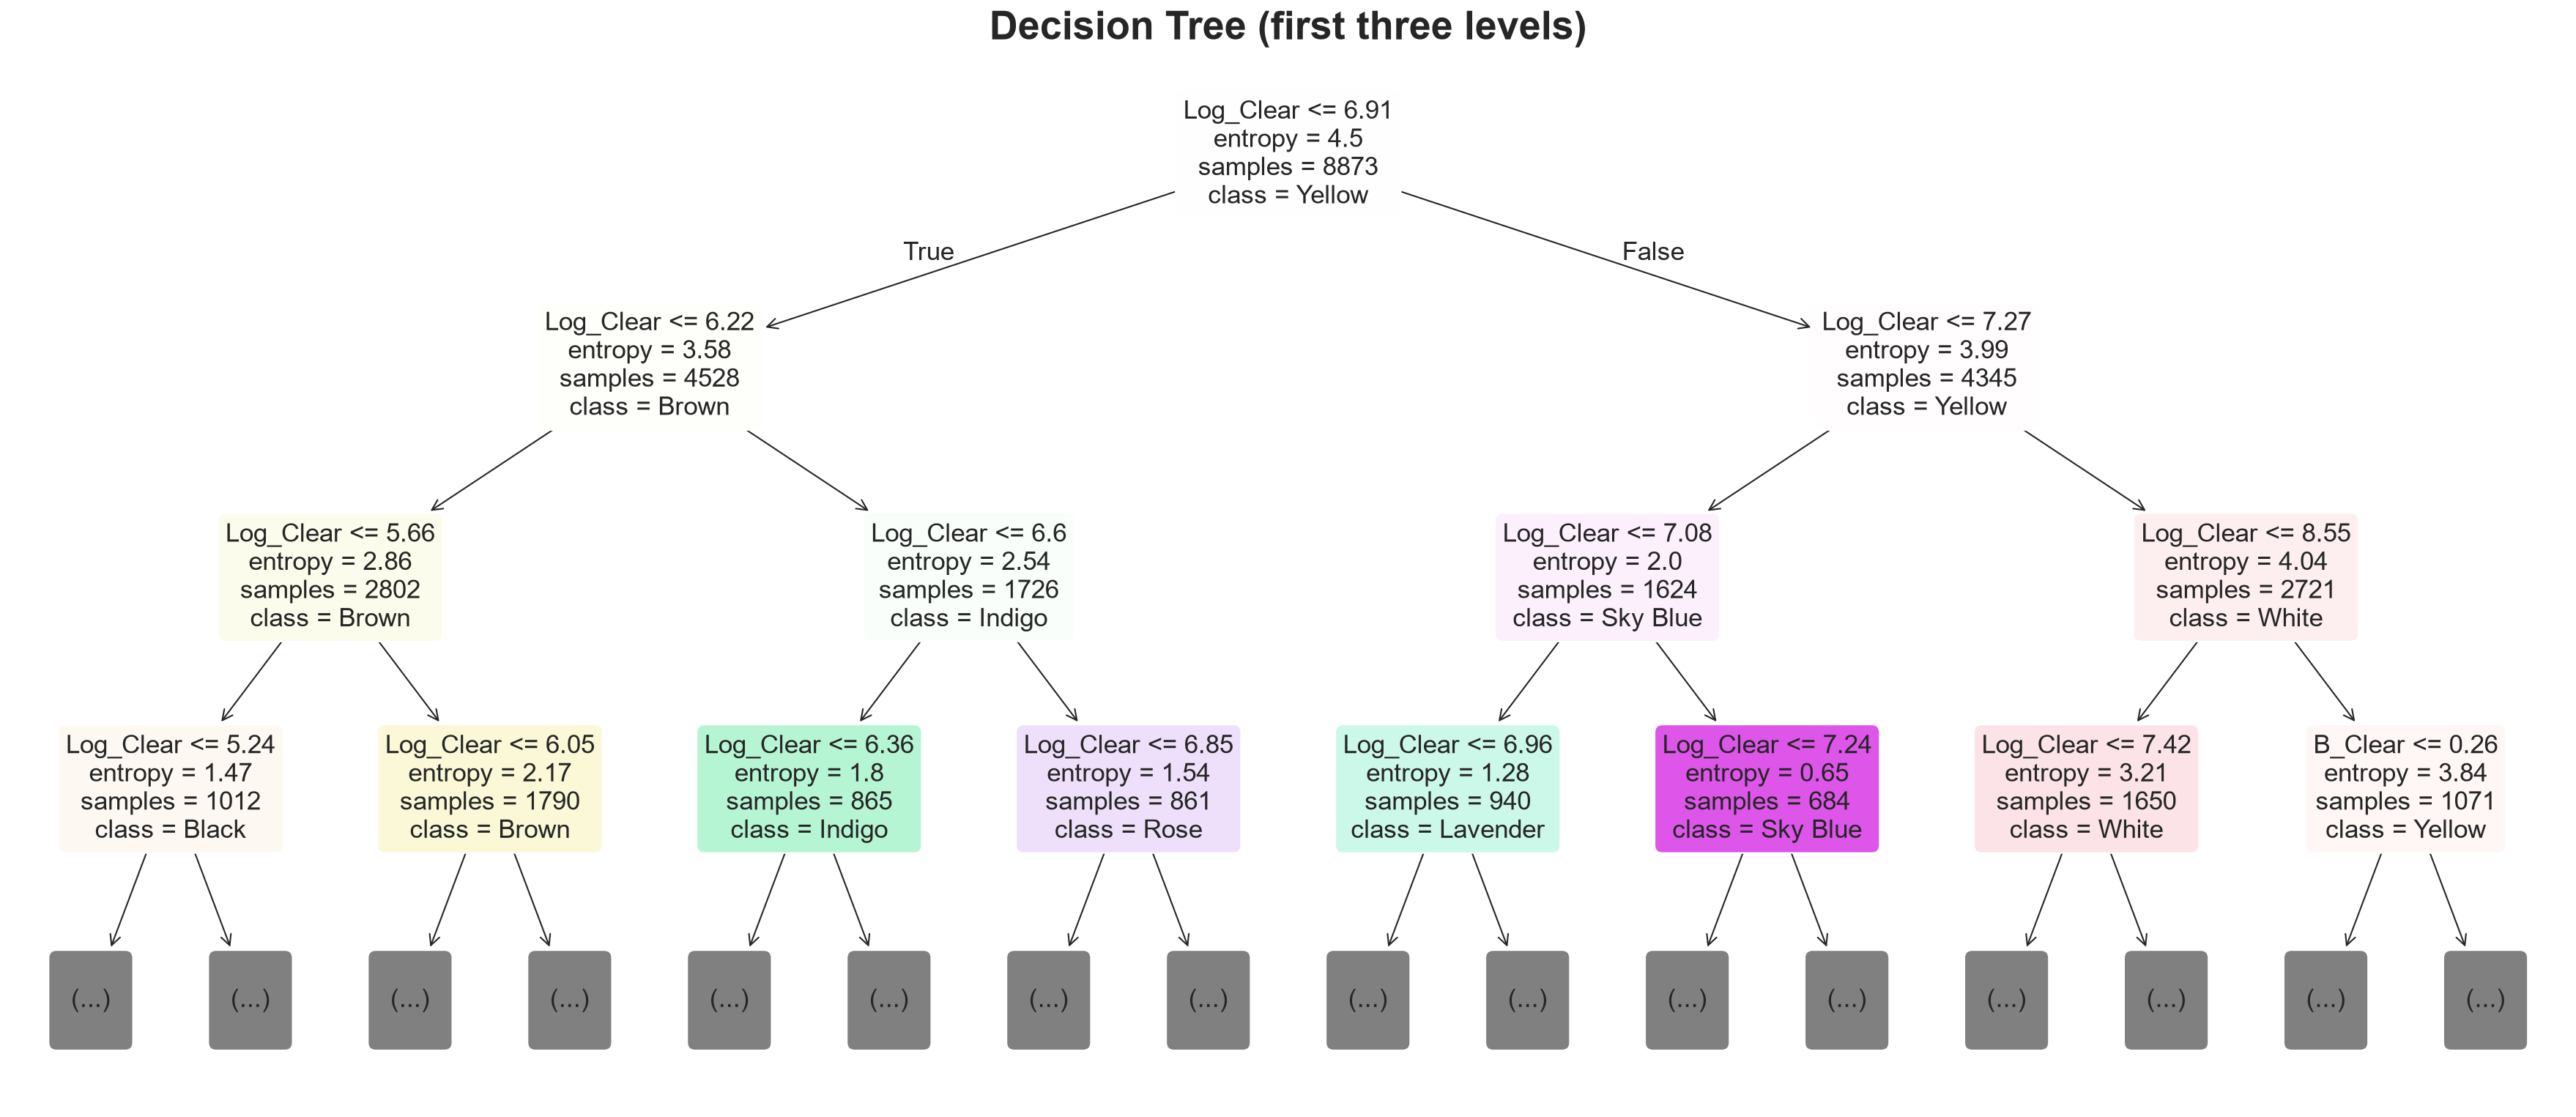

In [383]:
plt.figure(figsize=(30,12.5))
tree_plot=plot_tree(dt_model,feature_names=X.columns,class_names=sorted(y.unique()),filled=True,rounded=True,impurity=True,precision=2,fontsize=17,max_depth=3)
#remove the long 32-number "value" list from each box so the tree is readable
for node in tree_plot:
    keep=[]
    skip=False
    for line in node.get_text().split("\n"):
        if line.startswith("value"):
            skip=True
            continue
        if line.startswith("class"):
            skip=False
        if not skip:
            keep.append(line)
    node.set_text("\n".join(keep))
plt.title('Decision Tree (first three levels)')
plt.show()

In [384]:
print("Tree Depth",dt_model.get_depth())
print("Number of leaves:",dt_model.get_n_leaves())

Tree Depth 20
Number of leaves: 236


**NAIVE BAYES**

In [385]:
gnb=GaussianNB()
gnb.fit(X_train,y_train)
y_pred_nb=gnb.predict(X_test)

In [386]:
accuracy_nb=accuracy_score(y_test,y_pred_nb)
precision_nb=precision_score(y_test,y_pred_nb,average='weighted')
recall_nb=recall_score(y_test,y_pred_nb,average='weighted')
f1_nb=f1_score(y_test,y_pred_nb,average='weighted')
print("=========MODEL PERFORMANCE=========")
print("Accuracy:",accuracy_nb*100,"%")
print("Precision:",precision_nb*100,"%")
print("Recall:",recall_nb*100,"%")
print("F1 Score:",f1_nb*100,"%")

=========MODEL PERFORMANCE=========
Accuracy: 45.5610635421361 %
Precision: 45.28593038563011 %
Recall: 45.5610635421361 %
F1 Score: 43.69675020632529 %


In [387]:
smoothing_values=[1e-12,1e-10,1e-9,1e-8,1e-7,1e-6,1e-5,1e-4,1e-3,1e-2]
result=[]
for var in smoothing_values:
    model=GaussianNB(var_smoothing=var)
    model.fit(X_train,y_train)
    prediction=model.predict(X_test)
    result.append([var,accuracy_score(y_test,prediction),f1_score(y_test,prediction,average='weighted')])
results_df=pd.DataFrame(result,columns=["var_smoothing","accuracy","f1"])
print(results_df)

   var_smoothing  accuracy        f1
0   1.000000e-12  0.455611  0.436968
1   1.000000e-10  0.455611  0.436968
2   1.000000e-09  0.455611  0.436968
3   1.000000e-08  0.455611  0.436968
4   1.000000e-07  0.455611  0.436968
5   1.000000e-06  0.454259  0.435788
6   1.000000e-05  0.448400  0.428875
7   1.000000e-04  0.442542  0.418726
8   1.000000e-03  0.420910  0.392414
9   1.000000e-02  0.381253  0.341660


**MODEL COMPARISON**

In [388]:
def family_accuracy(y_true,y_pred):
    return accuracy_score([FAMILY[v] for v in y_true],[FAMILY[v] for v in y_pred])

final_comparison=pd.DataFrame({
    "Model":["Decision Tree","Naive Bayes","KNN"],
    "Accuracy":[accuracy_dt,accuracy_nb,accuracy_knn],
    "Precision":[precision_dt,precision_nb,precision_knn],
    "Recall":[recall_dt,recall_nb,recall_knn],
    "F1 Score":[f1_dt,f1_nb,f1_knn],
    "Colour Family Accuracy":[family_accuracy(y_test,p) for p in [y_pred_dt,y_pred_nb,y_pred_knn]]
})
final_comparison.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,Colour Family Accuracy
0,Decision Tree,0.975,0.976,0.975,0.975,0.978
1,Naive Bayes,0.456,0.453,0.456,0.437,0.504
2,KNN,0.428,0.440,0.428,0.423,0.453


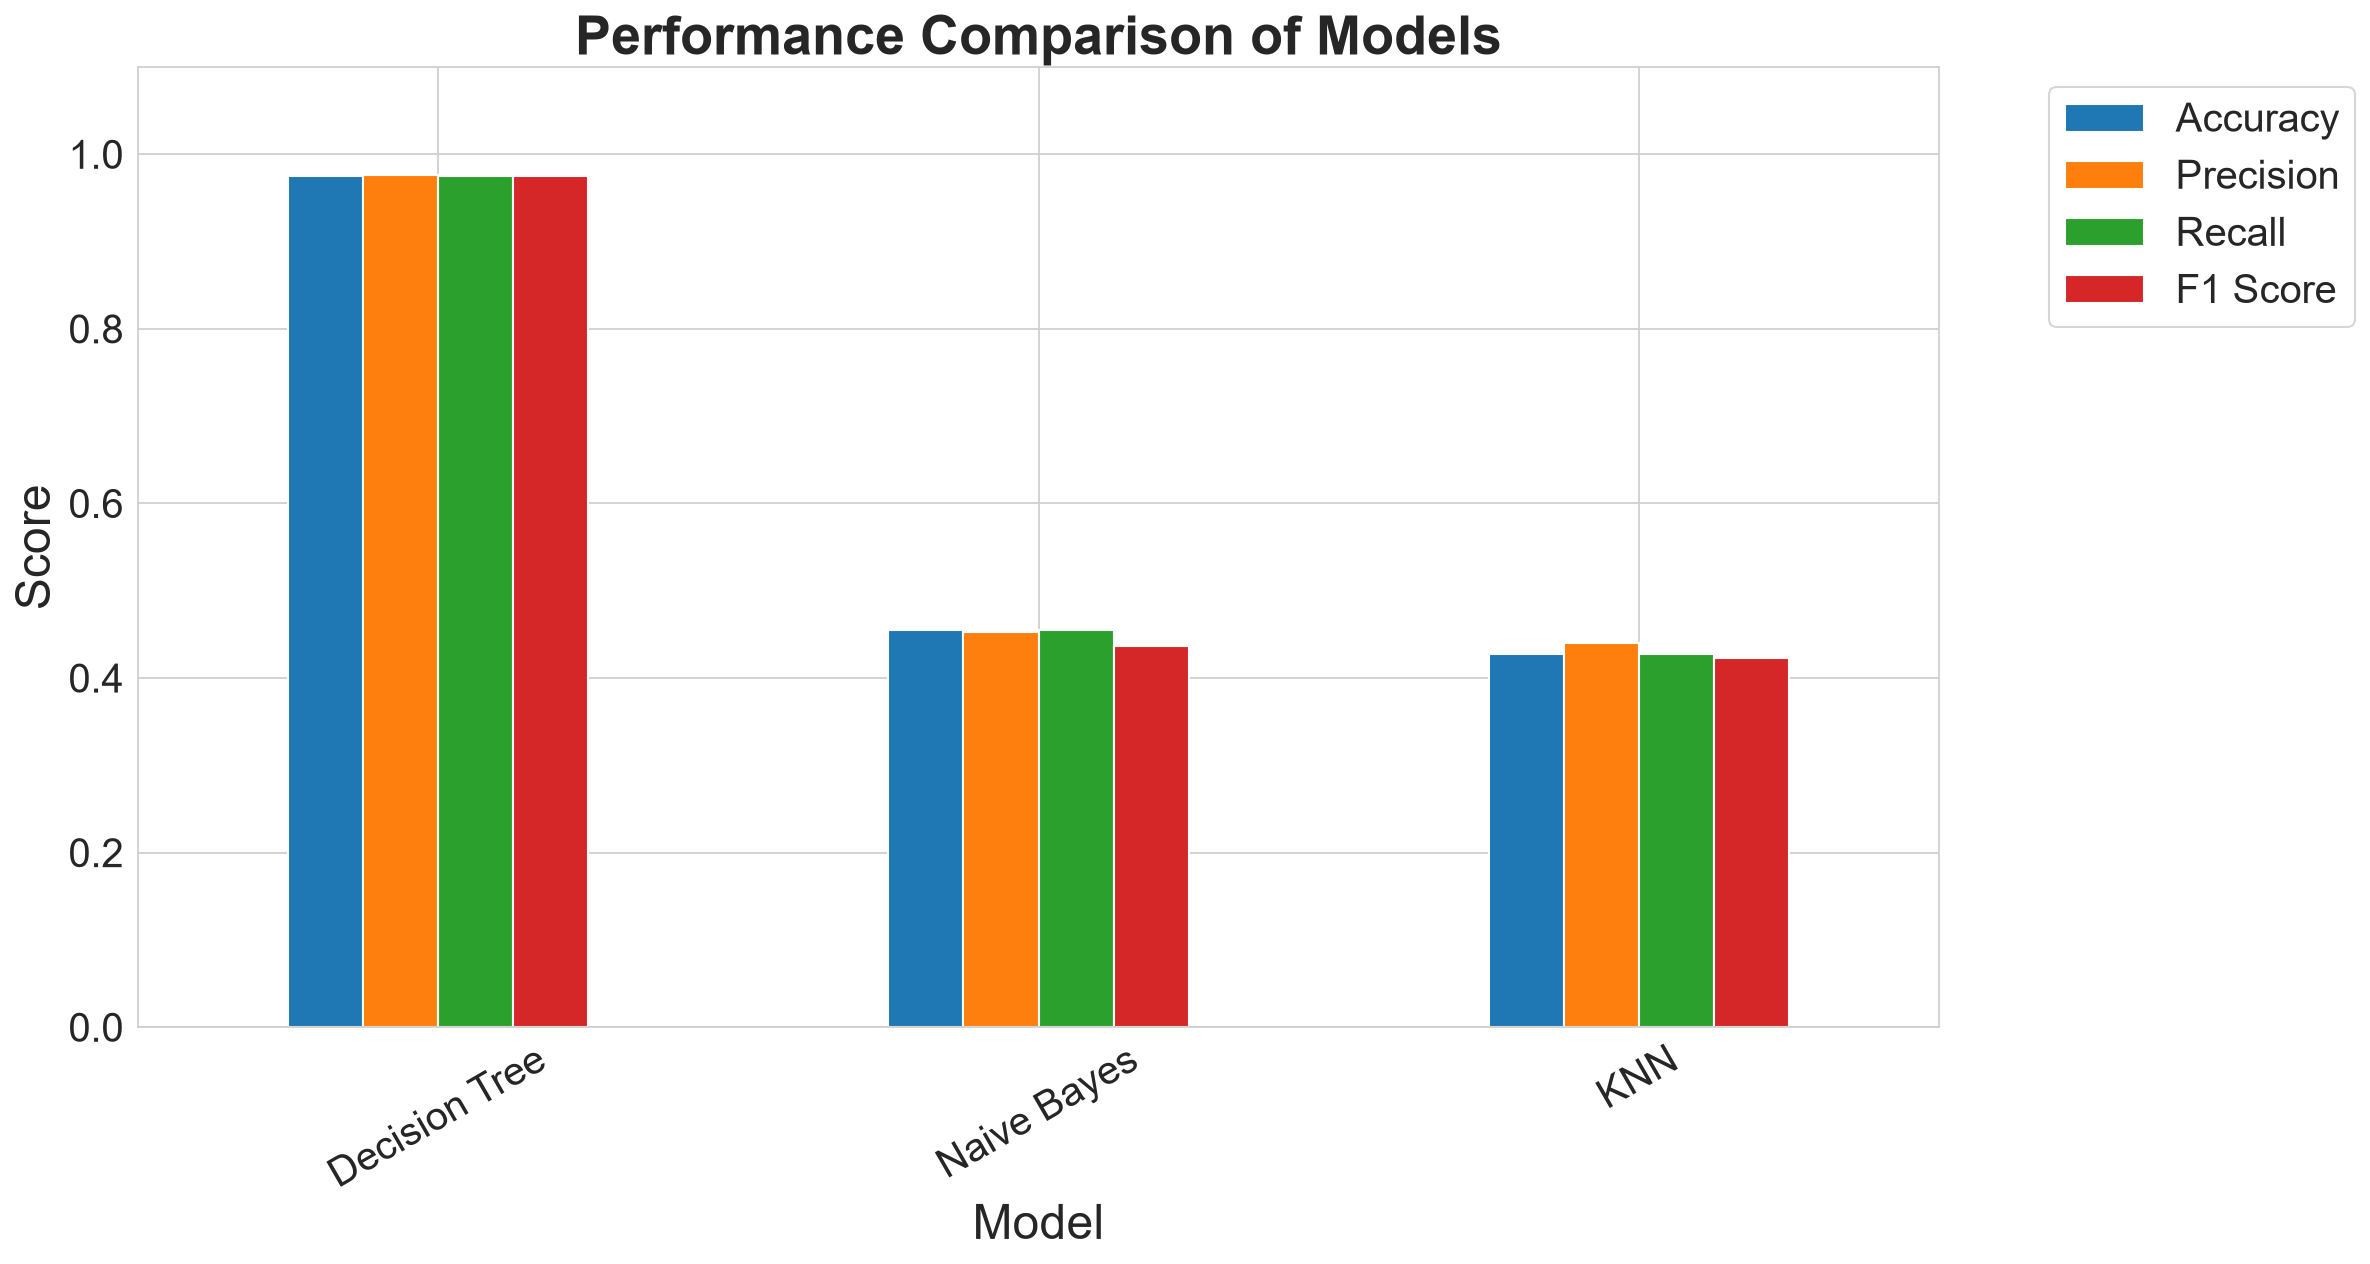

In [389]:
final_comparison.set_index("Model")[["Accuracy","Precision","Recall","F1 Score"]].plot(kind="bar",figsize=(16.2,8.8))
plt.title("Performance Comparison of Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0,1.1)
plt.xticks(rotation=30)
plt.legend(bbox_to_anchor=(1.05,1),loc="upper left")
plt.tight_layout()
plt.show()

**HYPERPARAMETER TUNING (GridSearchCV)**

In [390]:
#Decision Tree
param_grid_dt={
    'criterion':['entropy','gini'],
    'max_depth':[5,10,15,20,None],
    'min_samples_split':[2,5,10],
    'min_samples_leaf':[1,2,4],
    'ccp_alpha':[0,0.0005,0.001]
}
grid_dt=GridSearchCV(DecisionTreeClassifier(random_state=42),param_grid_dt,cv=5,scoring='accuracy',n_jobs=-1)
grid_dt.fit(X_train,y_train)
print("Best Parameters")
print(grid_dt.best_params_)
print("Best Cross Validation Accuracy")
print(grid_dt.best_score_)
best_tree=grid_dt.best_estimator_
y_pred_tdt=best_tree.predict(X_test)

Best Parameters
{'ccp_alpha': 0.0005, 'criterion': 'entropy', 'max_depth': 15, 'min_samples_leaf': 1, 'min_samples_split': 5}
Best Cross Validation Accuracy
0.9788111850358068


In [391]:
#KNN
param_grid_knn={
    'n_neighbors':[1,3,5,7,9,11,15],
    'weights':['uniform','distance'],
    'p':[1,2]
}
grid_knn=GridSearchCV(KNeighborsClassifier(),param_grid_knn,cv=5,scoring='accuracy',n_jobs=-1)
grid_knn.fit(X_train_scaled,y_train)
print("Best Parameters")
print(grid_knn.best_params_)
print("Best Cross Validation Accuracy")
print(grid_knn.best_score_)
best_knn=grid_knn.best_estimator_
y_pred_tknn=best_knn.predict(X_test_scaled)

Best Parameters
{'n_neighbors': 15, 'p': 1, 'weights': 'distance'}
Best Cross Validation Accuracy
0.45486377566413133


In [392]:
tuned_comparison=pd.DataFrame({
    "Model":["Decision Tree","KNN"],
    "Before Tuning":[accuracy_dt,accuracy_knn],
    "After Tuning":[accuracy_score(y_test,y_pred_tdt),accuracy_score(y_test,y_pred_tknn)],
    "CV Accuracy (train)":[grid_dt.best_score_,grid_knn.best_score_]
})
tuned_comparison.round(3)

,Model,Before Tuning,After Tuning,CV Accuracy (train)
0,Decision Tree,0.975,0.975,0.979
1,KNN,0.428,0.476,0.455


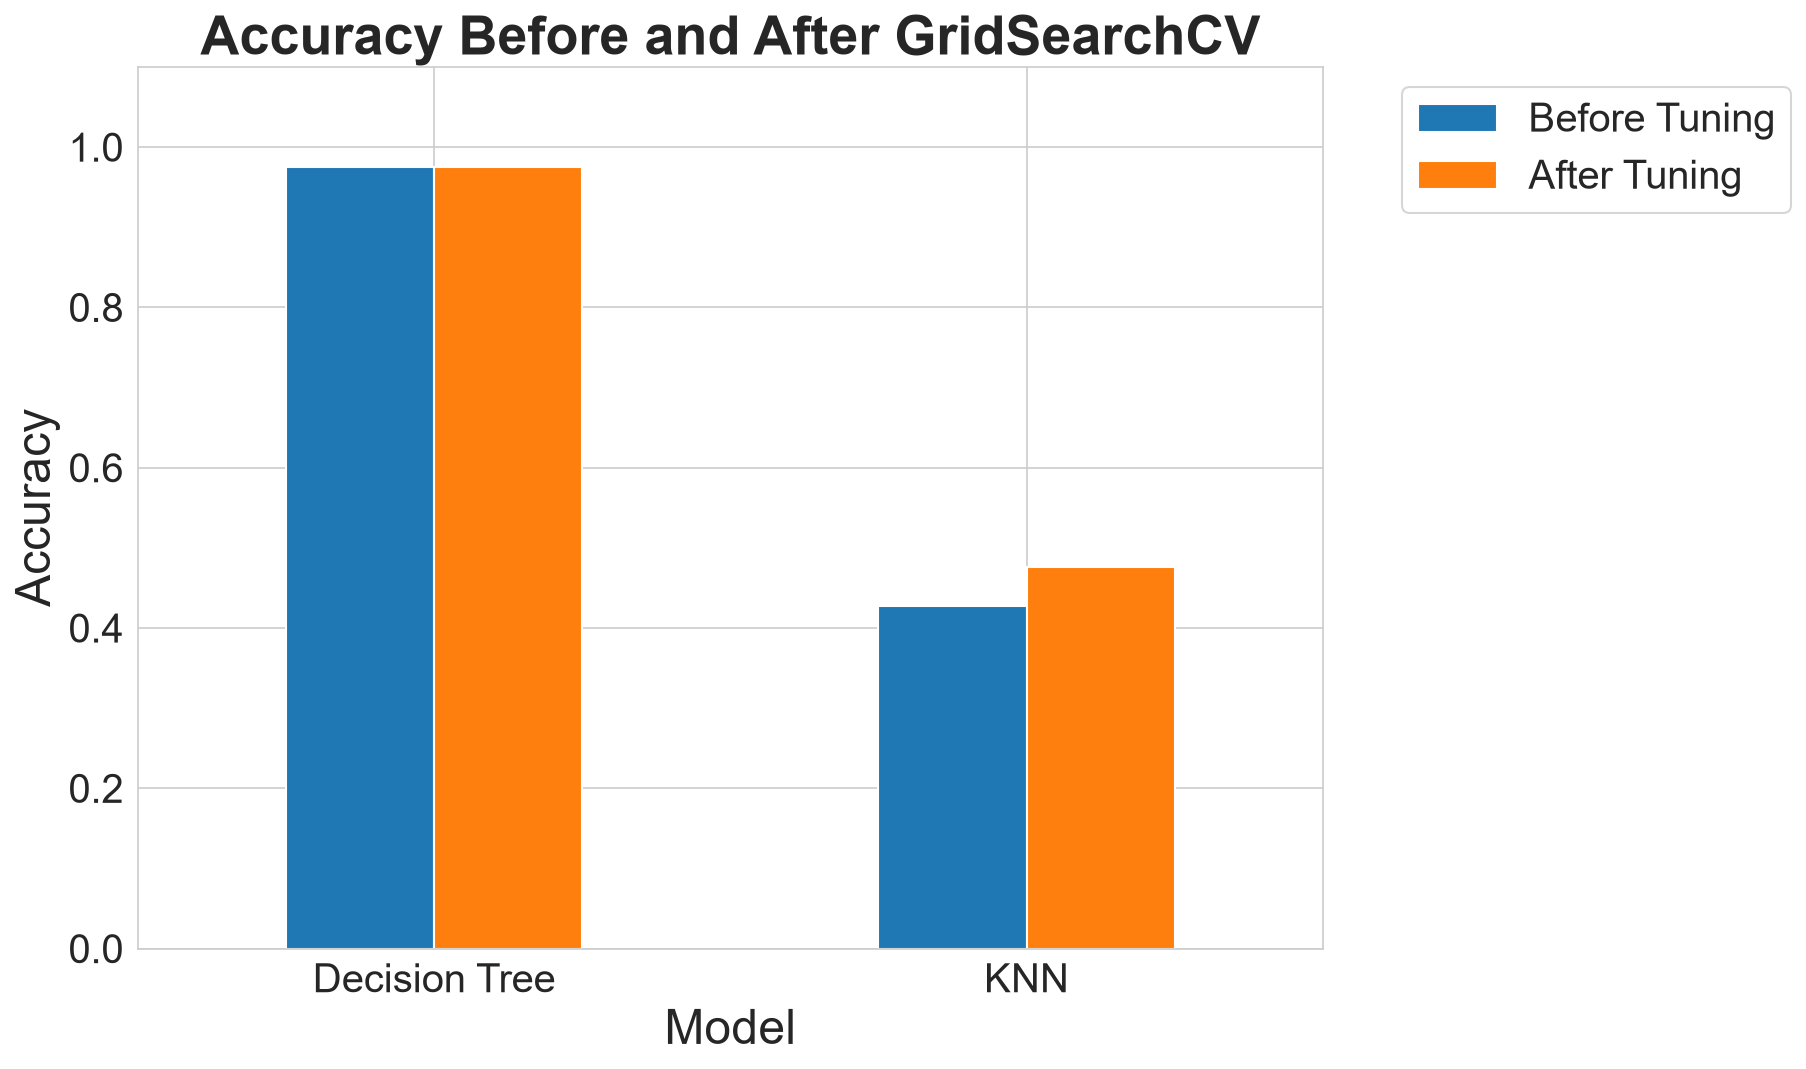

In [393]:
tuned_comparison.set_index("Model")[["Before Tuning","After Tuning"]].plot(kind="bar",figsize=(12.5,7.5))
plt.title("Accuracy Before and After GridSearchCV")
plt.ylabel("Accuracy")
plt.ylim(0,1.1)
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.05,1),loc="upper left")
plt.tight_layout()
plt.show()

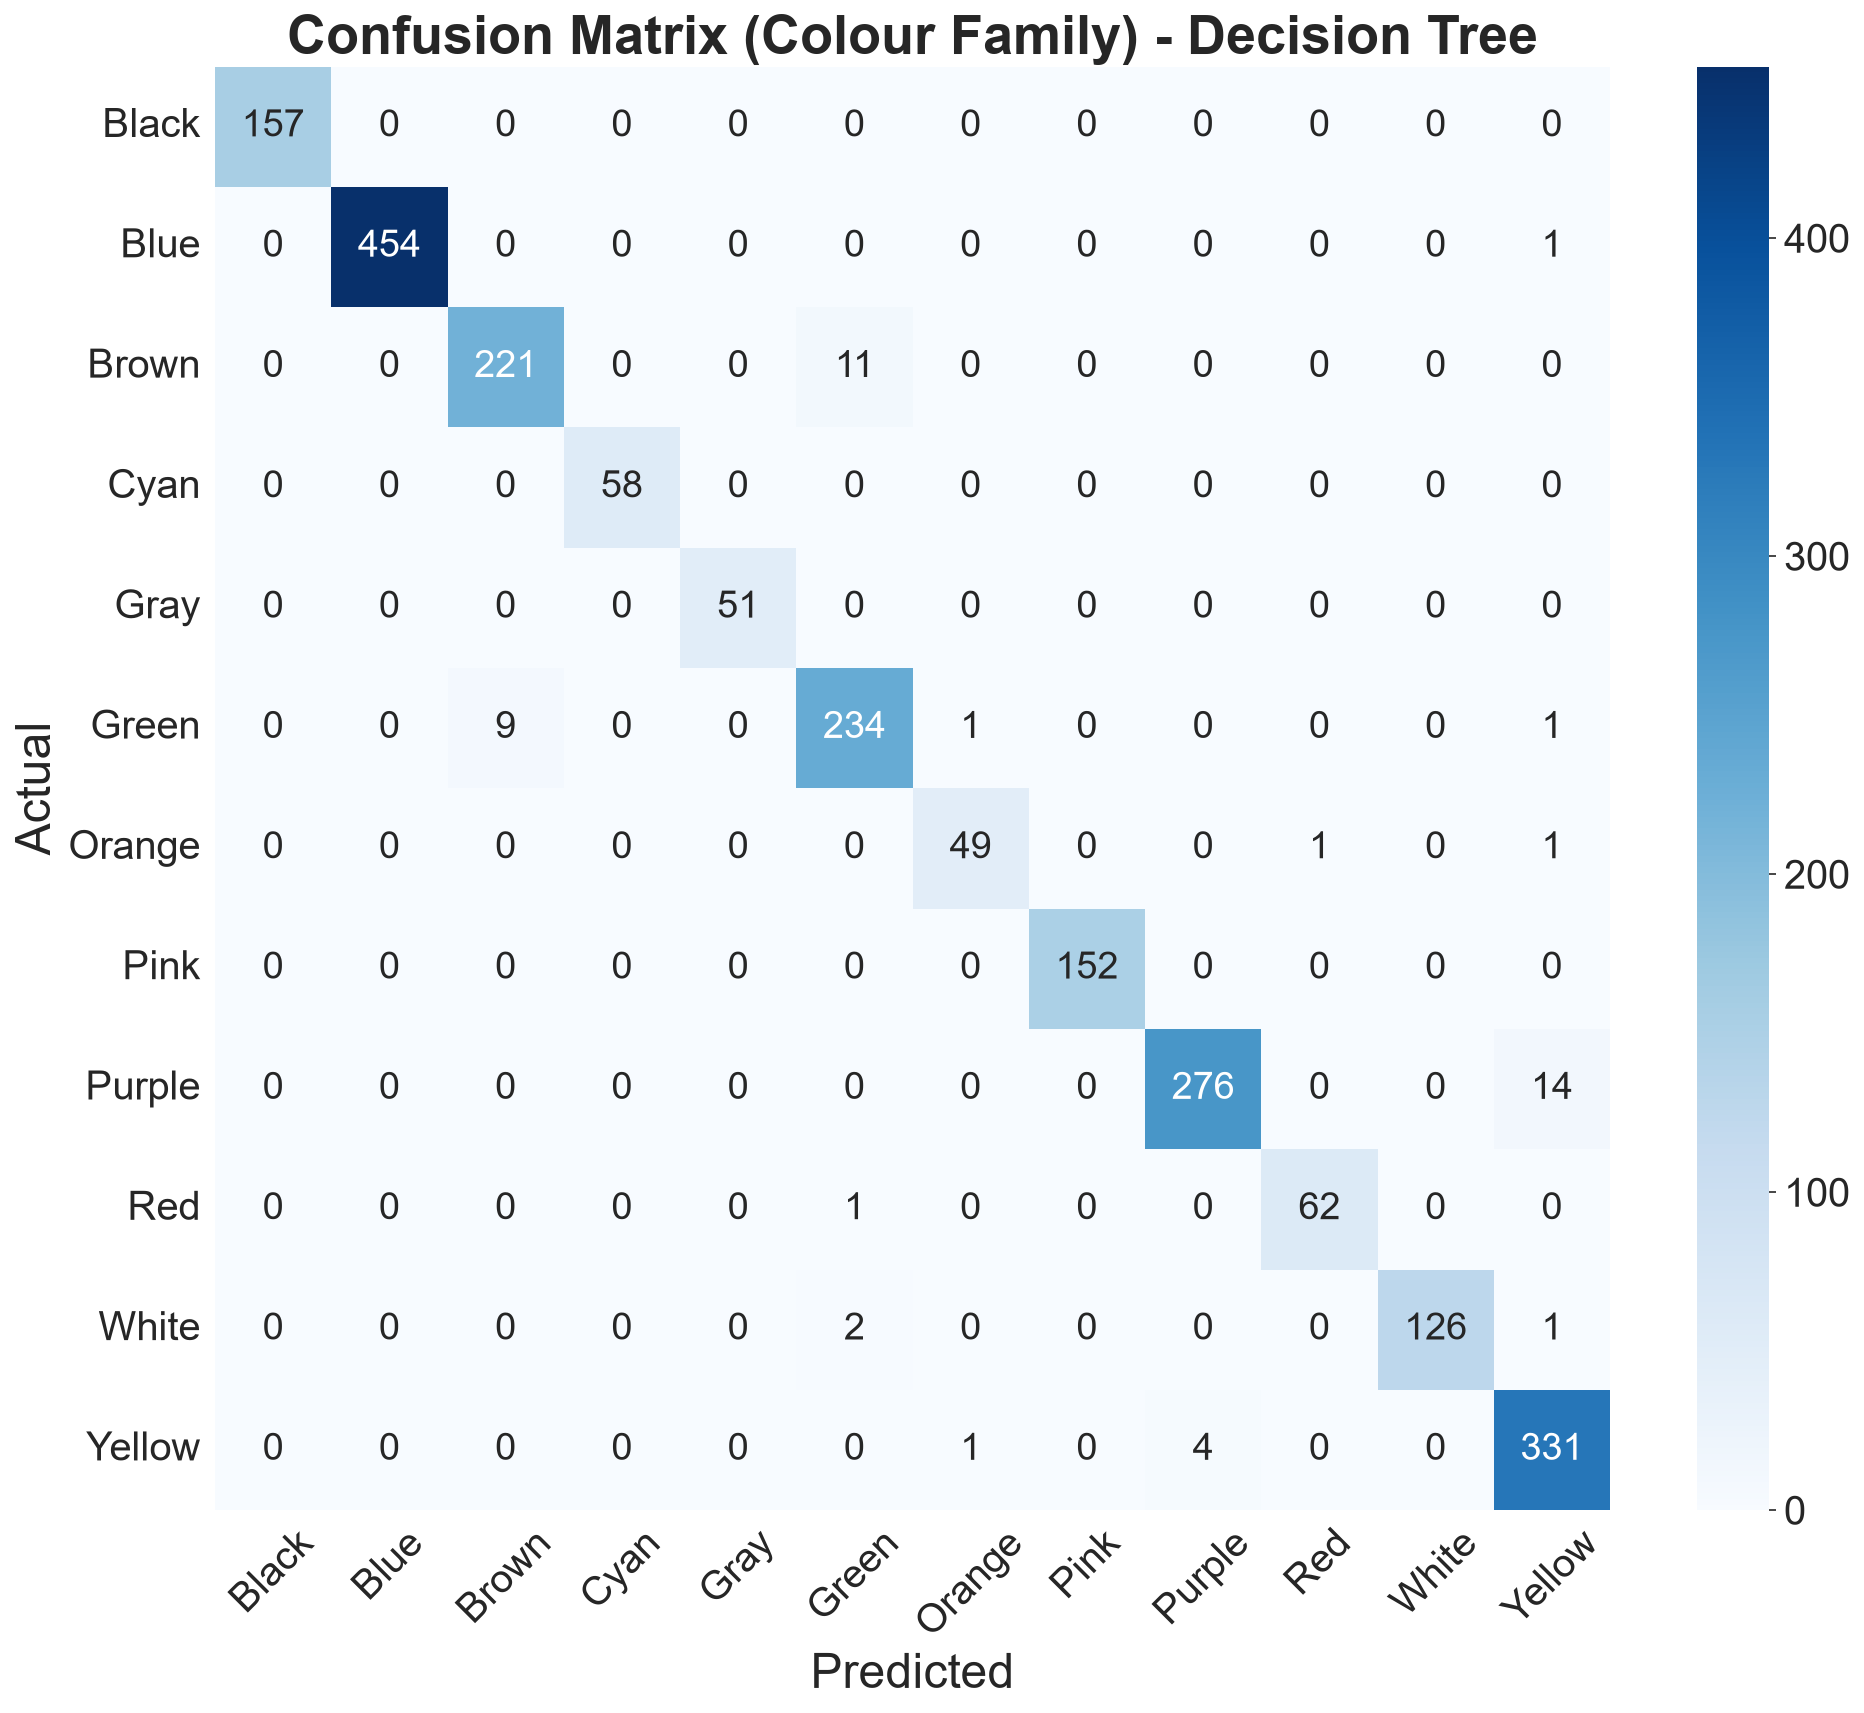

In [394]:
fam_true=[FAMILY[v] for v in y_test]
fam_pred=[FAMILY[v] for v in y_pred_dt]
labels=sorted(set(fam_true))
cm=confusion_matrix(fam_true,fam_pred,labels=labels)
plt.figure(figsize=(15,12.5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=labels,yticklabels=labels,annot_kws={"size":18})
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.title("Confusion Matrix (Colour Family) - Decision Tree")
plt.show()

In [395]:
print(classification_report(y_test,y_pred_dt,zero_division=0))

              precision    recall  f1-score   support

       Amber       0.86      0.75      0.80        16
       Black       1.00      1.00      1.00       157
        Blue       1.00      0.96      0.98        27
       Brown       0.95      0.94      0.94       177
Brown-Orange       0.79      0.88      0.83        17
        Cyan       1.00      1.00      1.00        19
   Dark Blue       1.00      1.00      1.00       126
  Dark Green       0.94      1.00      0.97        17
      Golden       1.00      1.00      1.00       134
        Gray       1.00      1.00      1.00        51
       Green       0.88      0.91      0.90       117
      Indigo       1.00      1.00      1.00       115
    Lavender       0.97      0.89      0.93       128
        Lime       1.00      1.00      1.00        55
      Maroon       1.00      1.00      1.00        17
     Mustard       0.94      1.00      0.97        16
       Olive       0.95      0.95      0.95        37
      Orange       1.00    

**WHICH FEATURES MATTER? (Decision Tree)**

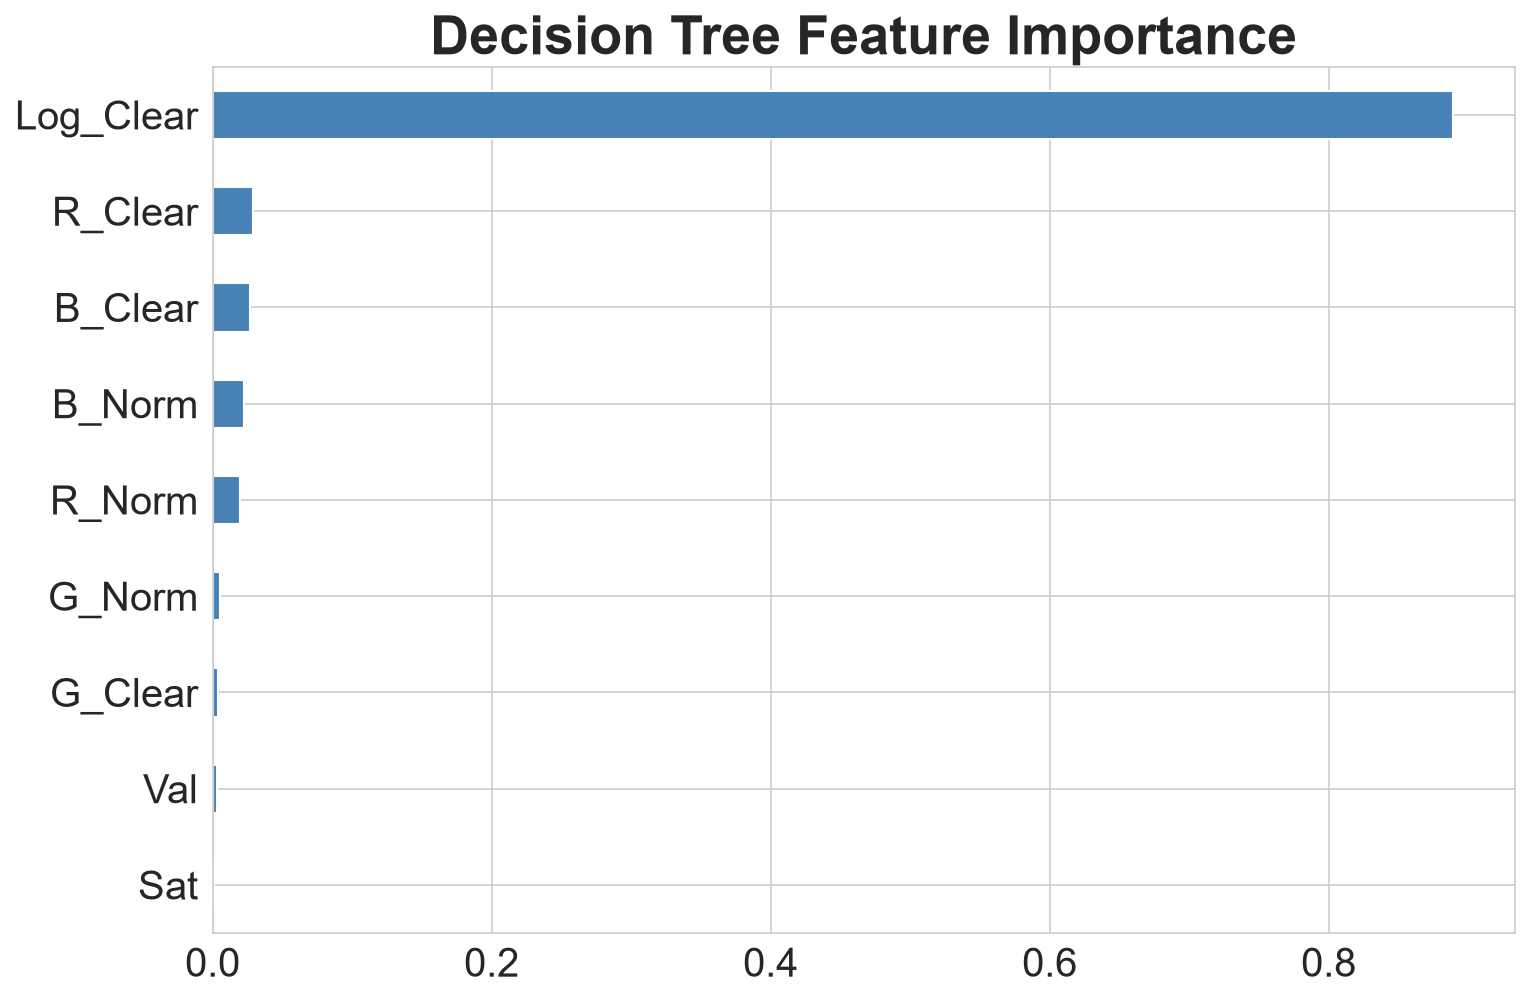

In [396]:
imp=pd.Series(dt_model.feature_importances_,index=X.columns).sort_values()
plt.figure(figsize=(11.2,7.5))
imp.plot(kind="barh",color="steelblue")
plt.title("Decision Tree Feature Importance")
plt.show()

In [397]:
brightness_only=["Log_Clear"]
colour_only=["R_Norm","G_Norm","B_Norm","Sat","Val"]

dt_b=DecisionTreeClassifier(criterion='entropy',random_state=42)
dt_b.fit(X_train[brightness_only],y_train)
print("Brightness only accuracy:",accuracy_score(y_test,dt_b.predict(X_test[brightness_only])))

dt_c=DecisionTreeClassifier(criterion='entropy',random_state=42)
dt_c.fit(X_train[colour_only],y_train)
print("Colour only accuracy:",accuracy_score(y_test,dt_c.predict(X_test[colour_only])))

Brightness only accuracy: 0.9013068949977467
Colour only accuracy: 0.170797656602073


Brightness (`Log_Clear`) alone gives most of the accuracy, while colour ratios alone are much weaker. In this dataset each shade was logged at its own light level, so this is a limit of the data, not of the algorithms. Logging every shade at several LED levels is the next step.

**TEST CASES**

In [398]:
#Test Case 1 - random readings from the unseen test data (true colour known)
sample=X_test.sample(10,random_state=3)
test_cases=pd.DataFrame({
    "Red":df.loc[sample.index,"Red"],
    "Green":df.loc[sample.index,"Green"],
    "Blue":df.loc[sample.index,"Blue"],
    "Clear":df.loc[sample.index,"Clear"],
    "Actual Colour":y_test.loc[sample.index],
    "Predicted Colour":dt_model.predict(sample)
})
test_cases["Result"]=np.where(test_cases["Actual Colour"]==test_cases["Predicted Colour"],"Correct","Wrong")
test_cases.reset_index(drop=True)

,Red,Green,Blue,Clear,Actual Colour,Predicted Colour,Result
0,0,409,102,1069,Dark Blue,Dark Blue,Correct
1,201,938,620,1588,White,White,Correct
2,0,248,0,359,Yellow,Yellow,Correct
3,254,1065,761,1423,Sky Blue,Sky Blue,Correct
4,582,407,579,1033,Lavender,Lavender,Correct
5,264,359,23,707,Lime,Lime,Correct
6,307,511,409,1625,White,White,Correct
7,355,862,457,1415,Sky Blue,Sky Blue,Correct
8,343,0,0,208,Dark Blue,Dark Blue,Correct
9,278,505,303,1038,Lavender,Lavender,Correct


In [399]:
#Test Case 2 - typed-in sensor readings (Red, Green, Blue, Clear)

cases=[("Red surface",2079,707,276,3136),
       ("Green surface",0,0,434,461),
       ("Sky Blue surface",51,406,913,1430),
       ("Yellow surface",529,333,410,1041),
       ("White paper",1696,1896,1408,5157),
       ("Black object",0,199,85,176),
       ("Purple surface",0,337,198,457),
       ("Pink surface",659,710,609,2030)]
cases=pd.DataFrame(cases,columns=["Surface","Red","Green","Blue","Clear"]).values.tolist()

In [400]:
new_samples=pd.DataFrame(cases,columns=["Surface","Red","Green","Blue","Clear"])
new_features=make_features(new_samples)
output=new_samples.copy()
output["Predicted Colour"]=dt_model.predict(new_features)
output["Colour Family"]=[FAMILY[c] for c in output["Predicted Colour"]]
output

,Surface,Red,Green,Blue,Clear,Predicted Colour,Colour Family
0,Red surface,2079,707,276,3136,Red,Red
1,Green surface,0,0,434,461,Green,Green
2,Sky Blue surface,51,406,913,1430,Sky Blue,Blue
3,Yellow surface,529,333,410,1041,Yellow,Yellow
4,White paper,1696,1896,1408,5157,White,White
5,Black object,0,199,85,176,Black,Black
6,Purple surface,0,337,198,457,Purple,Purple
7,Pink surface,659,710,609,2030,Pink,Pink


In [401]:
#Test Case 3 - what every algorithm says for the same reading
reading=pd.DataFrame({"Red":[cases[2][1]],"Green":[cases[2][2]],"Blue":[cases[2][3]],"Clear":[cases[2][4]]})
reading_features=make_features(reading)
print("Reading:",cases[2])
print("Decision Tree  :",dt_model.predict(reading_features)[0])
print("Naive Bayes    :",gnb.predict(reading_features)[0])
print("KNN            :",knn.predict(scaler_class.transform(reading_features))[0])

Reading: ['Sky Blue surface', 51, 406, 913, 1430]
Decision Tree  : Sky Blue
Naive Bayes    : Sky Blue
KNN            : Sky Blue


In [402]:
#Test Case 4 - distance check of the device (valid range 2 mm to 10 mm)
def check_distance(distance_mm):
    if distance_mm<2:
        return "Move back"
    elif distance_mm>10:
        return "Move closer"
    else:
        return "OK"

for d in [1,5,25]:
    print("Distance",d,"mm ->",check_distance(d))

Distance 1 mm -> Move back
Distance 5 mm -> OK
Distance 25 mm -> Move closer


**TEST CASE 5 - LIVE INPUT (type the sensor reading and run the cell)**

In [403]:
red=float(input("Enter Red:"))
green=float(input("Enter Green:"))
blue=float(input("Enter Blue:"))
clear=float(input("Enter Clear:"))
distance=float(input("Enter Distance in mm:"))

if check_distance(distance)!="OK":
    print(check_distance(distance))
else:
    new_sample=pd.DataFrame({"Red":[red],"Green":[green],"Blue":[blue],"Clear":[clear]})
    new_features=make_features(new_sample)
    prediction=dt_model.predict(new_features)
    print("Predicted Colour:",prediction[0])
    print("Colour Family:",FAMILY[prediction[0]])

Predicted Colour: Mustard
Colour Family: Yellow


**SUMMARY**
- **Data:** 11,092 TCS34725 readings (Red, Green, Blue, Clear) with 32 colour labels. EDA showed no missing sensor values, imbalanced classes, high-side outliers from bright surfaces, and colour clusters in ratio space.
- **Features:** 9 brightness-independent features (colour ratios, saturation, value, log of Clear).
- **Algorithms:** Linear Regression, KNN Regression and Classification, Decision Tree, Naive Bayes.
- **Results (20 % unseen test data):** Decision Tree 97.5 %, Naive Bayes 45.6 %, KNN 42.8 %. For regression (Clear to Lux) KNN gave R2 0.994 against 0.929 for Linear Regression.
- **Hyperparameter tuning (GridSearchCV, 5-fold):** Decision Tree stays at 97.5 % (best: entropy, max_depth 15, ccp_alpha 0.0005) and KNN improves from 42.8 % to 47.6 % (k = 15, distance weights, Manhattan).
- **Final model:** the Decision Tree. Colour shades are separated by sharp thresholds on a few features, which a tree captures and distance or probability-based models do not.
- **Limits:** the tree reaches 100 % training accuracy, so part of its test accuracy comes from repeated near-identical readings of the same surface. Brightness alone gives about 90 % accuracy while colour ratios alone give about 17 %, because each shade was logged at its own light level. The data are pH-strip colours, so accuracy on everyday objects under new lighting will be lower; logging each shade at several LED levels is the next step.